In [ ]:
import os
from google.colab import userdata

token = userdata.get('KAGGLE_API_TOKEN')
os.makedirs("/root/.kaggle", exist_ok=True)
with open("/root/.kaggle/access_token", "w") as f:
    f.write(token)
os.chmod("/root/.kaggle/access_token", 0o600)
print("Kaggle token saved securely.")

Kaggle token saved securely.


In [ ]:
!pip install -q kaggle
!kaggle datasets download -d samyakjhaveri/mooc-final

Dataset URL: https://www.kaggle.com/datasets/samyakjhaveri/mooc-final
License(s): CC0-1.0
100% 362M/362M [00:10<00:00, 37.3MB/s]



In [ ]:
!unzip -q mooc-final.zip -d mooc_data
import os
print(os.listdir("mooc_data"))

['train', 'test', 'model1.model']


In [ ]:
 import os
print(os.listdir("mooc_data/train"))

['train.csv']


In [ ]:
import pandas as pd

# Reading just the first 5 rows to peek without loading all 29 million rows
df_preview = pd.read_csv("mooc_data/train/train.csv", nrows=5)
print(df_preview.columns.tolist())
df_preview

['Unnamed: 0', 'enroll_id', 'username', 'course_id', 'session_id', 'action', 'object', 'time', 'truth']


,Unnamed: 0,enroll_id,username,course_id,session_id,action,object,time,truth
0,0,772,5981,course-v1:TsinghuaX+70800232X+2015_T2,d8a9b787fa69063c34c73b9c29190b1c,click_about,NaN,2015-09-27T15:42:59,1
1,1,772,5981,course-v1:TsinghuaX+70800232X+2015_T2,d8a9b787fa69063c34c73b9c29190b1c,click_info,NaN,2015-09-27T15:43:12,1
2,2,773,1544995,course-v1:TsinghuaX+70800232X+2015_T2,2f02b86eb3ea2cbf0be11385a8dc62e5,pause_video,3dac5590435e43b3a65a9ae7426c16db,2015-10-19T19:37:42,1
3,3,773,1544995,course-v1:TsinghuaX+70800232X+2015_T2,2f02b86eb3ea2cbf0be11385a8dc62e5,load_video,3dac5590435e43b3a65a9ae7426c16db,2015-10-19T19:33:27,1
4,4,773,1544995,course-v1:TsinghuaX+70800232X+2015_T2,2f02b86eb3ea2cbf0be11385a8dc62e5,play_video,3dac5590435e43b3a65a9ae7426c16db,2015-10-19T19:33:30,1


In [ ]:
# =============================================================================
# STEP 1b: AGGREGATING RAW CLICKSTREAM LOGS INTO PER-STUDENT FEATURES
# Predicting Student Dropout Risk in Online Learning
# Source: mooc_data/train/train.csv (~29 million click-event rows)
# Goal: one row per enroll_id, with summary features + the dropout label (truth)
# =============================================================================

import pandas as pd

# -----------------------------------------------------------------------------
# Why we read in chunks:
# The raw file has ~29 million rows. Loading it all into memory at once risks
# crashing Colab. Instead, we read it in pieces ("chunks"), aggregate each
# piece, and combine the partial results at the end. This keeps memory usage
# low no matter how large the file is.
# -----------------------------------------------------------------------------

CHUNK_SIZE = 1_000_000  # process 1 million rows at a time
RAW_PATH = "mooc_data/train/train.csv"

# We will build up per-student counts as we go, using a dictionary of
# partial DataFrames that we combine at the very end.
chunk_results = []

print("Starting chunked aggregation... this may take a few minutes.")

for i, chunk in enumerate(pd.read_csv(RAW_PATH, chunksize=CHUNK_SIZE)):

    # --- Basic per-student aggregates within this chunk ---
    # We group by enroll_id (one student's enrollment) and compute:
    #  - total number of actions (clicks) recorded
    #  - number of distinct days they were active
    #  - number of distinct sessions
    #  - counts of specific action types (video-related, problem-related, etc.)
    #  - the truth (dropout) label, which is constant per enroll_id

    chunk["time"] = pd.to_datetime(chunk["time"])
    chunk["date"] = chunk["time"].dt.date

    grouped = chunk.groupby("enroll_id").agg(
        total_clicks=("action", "count"),
        active_days=("date", "nunique"),
        active_sessions=("session_id", "nunique"),
        truth=("truth", "first"),
    )

    # --- Action-type specific counts ---
    # Pivot the action column so each action type becomes its own count column
    # e.g. 'play_video', 'pause_video', 'problem', 'discussion', etc.
    action_counts = (
        chunk.groupby(["enroll_id", "action"])
        .size()
        .unstack(fill_value=0)
    )

    chunk_summary = grouped.join(action_counts, how="left")
    chunk_results.append(chunk_summary)

    print(f"Processed chunk {i + 1} ({(i + 1) * CHUNK_SIZE:,} rows read so far)")

print("\nAll chunks processed. Combining partial results...")

# -----------------------------------------------------------------------------
# Combine partial chunk summaries
# Because the same enroll_id can appear across multiple chunks (its clicks
# might be split across chunk boundaries), we need to SUM the numeric columns
# across chunks for each enroll_id, rather than just concatenating.
# -----------------------------------------------------------------------------

combined = pd.concat(chunk_results)

# Columns that should be summed across chunks (counts)
count_cols = [c for c in combined.columns if c not in ["truth"]]

agg_dict = {col: "sum" for col in count_cols}
agg_dict["truth"] = "first"  # label doesn't change, just take it once

student_df = combined.groupby("enroll_id").agg(agg_dict).reset_index()

print(f"\nFinal aggregated dataset shape: {student_df.shape}")
print(f"(rows = unique student enrollments, columns = features + label)")

# -----------------------------------------------------------------------------
# Quick sanity check
# -----------------------------------------------------------------------------
print("\n--- Column names ---")
print(student_df.columns.tolist())

print("\n--- First 5 rows ---")
print(student_df.head())

print("\n--- Class distribution of 'truth' (dropout label) ---")
print(student_df["truth"].value_counts())
print(student_df["truth"].value_counts(normalize=True).round(4) * 100)

# -----------------------------------------------------------------------------
# Save the aggregated, student-level dataset so we don't have to redo this
# expensive aggregation every time we restart the notebook.
# -----------------------------------------------------------------------------
student_df.to_csv("mooc_student_level.csv", index=False)
print("\nSaved aggregated dataset to 'mooc_student_level.csv'")
print("This is now your STUDENT-LEVEL dataset — one row per enrollment.")
print("From here, we proceed to Step 1 profiling and Step 2 cleaning on THIS file.")

Starting chunked aggregation... this may take a few minutes.
Processed chunk 1 (1,000,000 rows read so far)
Processed chunk 2 (2,000,000 rows read so far)
Processed chunk 3 (3,000,000 rows read so far)
Processed chunk 4 (4,000,000 rows read so far)
Processed chunk 5 (5,000,000 rows read so far)
Processed chunk 6 (6,000,000 rows read so far)
Processed chunk 7 (7,000,000 rows read so far)
Processed chunk 8 (8,000,000 rows read so far)
Processed chunk 9 (9,000,000 rows read so far)
Processed chunk 10 (10,000,000 rows read so far)
Processed chunk 11 (11,000,000 rows read so far)
Processed chunk 12 (12,000,000 rows read so far)
Processed chunk 13 (13,000,000 rows read so far)
Processed chunk 14 (14,000,000 rows read so far)
Processed chunk 15 (15,000,000 rows read so far)
Processed chunk 16 (16,000,000 rows read so far)
Processed chunk 17 (17,000,000 rows read so far)
Processed chunk 18 (18,000,000 rows read so far)
Processed chunk 19 (19,000,000 rows read so far)
Processed chunk 20 (20,000

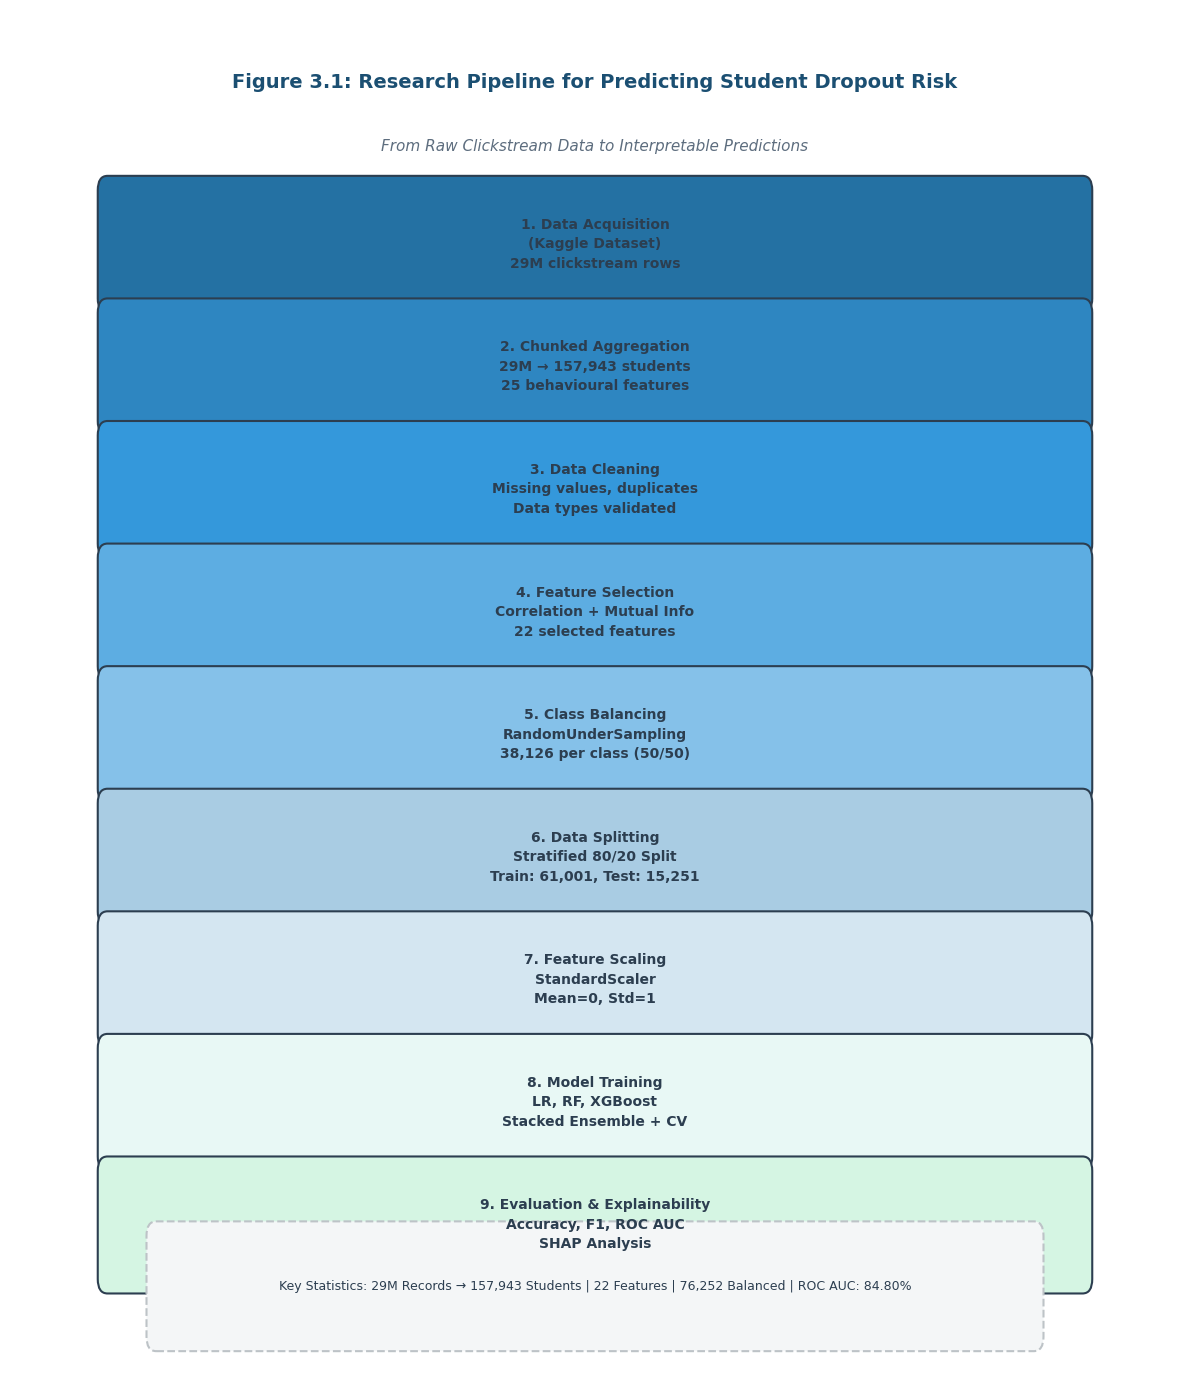


✅ FIGURE 3.1 GENERATED (SIMPLE VERSION)

📁 Saved as: fig_pipeline_diagram_simple.png
📍 Location: /content/

📥 Download from Colab file browser or right-click on image.


In [ ]:
# =============================================================================
# FIGURE 3.1: RESEARCH PIPELINE DIAGRAM (SIMPLE VERSION)
# =============================================================================

import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
import numpy as np

# Create figure
fig, ax = plt.subplots(1, 1, figsize=(12, 14))

# Define the 9 stages
stages = [
    "1. Data Acquisition\n(Kaggle Dataset)\n29M clickstream rows",
    "2. Chunked Aggregation\n29M → 157,943 students\n25 behavioural features",
    "3. Data Cleaning\nMissing values, duplicates\nData types validated",
    "4. Feature Selection\nCorrelation + Mutual Info\n22 selected features",
    "5. Class Balancing\nRandomUnderSampling\n38,126 per class (50/50)",
    "6. Data Splitting\nStratified 80/20 Split\nTrain: 61,001, Test: 15,251",
    "7. Feature Scaling\nStandardScaler\nMean=0, Std=1",
    "8. Model Training\nLR, RF, XGBoost\nStacked Ensemble + CV",
    "9. Evaluation & Explainability\nAccuracy, F1, ROC AUC\nSHAP Analysis"
]

# Colors
colors = ['#2471A3', '#2E86C1', '#3498DB', '#5DADE2', '#85C1E9',
          '#A9CCE3', '#D4E6F1', '#E8F8F5', '#D5F5E3']

# Box settings
box_width = 10
box_height = 0.75
x_start = 1
y_start = 7.5

for i, (stage, color) in enumerate(zip(stages, colors)):
    y_pos = y_start - i * 0.85

    # Create rounded rectangle
    box = FancyBboxPatch(
        (x_start, y_pos), box_width, box_height,
        boxstyle="round,pad=0.1",
        facecolor=color,
        edgecolor='#2C3E50',
        linewidth=1.5
    )
    ax.add_patch(box)

    # Add text (center aligned)
    ax.text(x_start + box_width/2, y_pos + box_height/2, stage,
            ha='center', va='center', fontsize=10, fontweight='bold',
            color='#2C3E50', linespacing=1.5)

    # Add arrow between stages
    if i < len(stages) - 1:
        arrow = FancyArrowPatch(
            (x_start + box_width/2, y_pos - 0.05),
            (x_start + box_width/2, y_pos - 0.75),
            arrowstyle='->,head_width=0.3,head_length=0.2',
            mutation_scale=20,
            color='#7F8C8D',
            linewidth=2
        )
        ax.add_patch(arrow)

# Title
ax.text(6, 9.0, 'Figure 3.1: Research Pipeline for Predicting Student Dropout Risk',
        ha='center', va='center', fontsize=14, fontweight='bold',
        color='#1B4F72')

# Subtitle
ax.text(6, 8.55, 'From Raw Clickstream Data to Interpretable Predictions',
        ha='center', va='center', fontsize=11, style='italic',
        color='#5D6D7E')

# Key stats box at bottom
stats_box = FancyBboxPatch(
    (1.5, 0.3), 9, 0.7,
    boxstyle="round,pad=0.1",
    facecolor='#F4F6F7',
    edgecolor='#BDC3C7',
    linewidth=1.5,
    linestyle='dashed'
)
ax.add_patch(stats_box)

stats_text = "Key Statistics: 29M Records → 157,943 Students | 22 Features | 76,252 Balanced | ROC AUC: 84.80%"
ax.text(6, 0.65, stats_text,
        ha='center', va='center', fontsize=9, color='#2C3E50')

# Remove axes
ax.set_xlim(0, 12)
ax.set_ylim(0, 9.5)
ax.axis('off')

plt.tight_layout()

# Save
plt.savefig('/content/fig_pipeline_diagram_simple.png', dpi=300, bbox_inches='tight', facecolor='white')
plt.show()

print("\n" + "=" * 60)
print("✅ FIGURE 3.1 GENERATED (SIMPLE VERSION)")
print("=" * 60)
print("\n📁 Saved as: fig_pipeline_diagram_simple.png")
print("📍 Location: /content/")
print("\n📥 Download from Colab file browser or right-click on image.")

In [ ]:
import shutil
import os

# Creates a folder in your Drive called "MOOC_Thesis_Data" if it doesn't exist
os.makedirs("/content/drive/MyDrive/MOOC_Thesis_Data", exist_ok=True)

shutil.copy("mooc_student_level.csv", "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_student_level.csv")

print("Saved to Google Drive: MOOC_Thesis_Data/mooc_student_level.csv")

Saved to Google Drive: MOOC_Thesis_Data/mooc_student_level.csv


In [ ]:
# =============================================================================
# STEP 2: DATA CLEANING
# Predicting Student Dropout Risk in Online Learning
# Source: mooc_student_level.csv (157,943 students x 27 columns)
# =============================================================================

import pandas as pd

# -----------------------------------------------------------------------------
# 2a. Load the student-level dataset (from Google Drive, so it persists
#     across sessions)
# -----------------------------------------------------------------------------


DATA_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_student_level.csv"
df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("STEP 2: DATA CLEANING")
print("=" * 70)
print(f"\nLoaded dataset shape: {df.shape}")

# -----------------------------------------------------------------------------
# 2b. Check for missing values
# -----------------------------------------------------------------------------
print("\n--- Missing values per column ---")
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_summary = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
missing_present = missing_summary[missing_summary["missing_count"] > 0]

if len(missing_present) == 0:
    print("No missing values found in any column.")
else:
    print(missing_present)
    print("\nNumeric columns with missing values will be imputed using the mean.")
    numeric_missing_cols = [
        c for c in missing_present.index if pd.api.types.is_numeric_dtype(df[c])
    ]
    for col in numeric_missing_cols:
        df[col] = df[col].fillna(df[col].mean())
    print(f"Imputed columns: {numeric_missing_cols}")

# -----------------------------------------------------------------------------
# 2c. Check data types (everything should be numeric except enroll_id,
#     which is an identifier, not a feature)
# -----------------------------------------------------------------------------
print("\n--- Data types ---")
print(df.dtypes)

non_numeric_cols = df.select_dtypes(exclude="number").columns.tolist()
print(f"\nNon-numeric columns: {non_numeric_cols}")
print("(enroll_id is expected here — it's an identifier, not a model feature, "
      "and will be excluded from training inputs, not encoded.)")

# -----------------------------------------------------------------------------
# 2d. Check for duplicate enroll_id rows
#     After aggregation, each enroll_id should appear exactly once.
# -----------------------------------------------------------------------------
duplicate_ids = df["enroll_id"].duplicated().sum()
print(f"\nDuplicate enroll_id rows: {duplicate_ids}")
if duplicate_ids > 0:
    print("WARNING: duplicates found — investigate the aggregation step.")
    df = df.drop_duplicates(subset="enroll_id", keep="first")
    print(f"Duplicates removed. New shape: {df.shape}")
else:
    print("Confirmed: one row per student enrollment, as expected.")

# -----------------------------------------------------------------------------
# 2e. Sanity check value ranges
#     Counts should never be negative. This catches any aggregation bugs.
# -----------------------------------------------------------------------------
count_cols = [c for c in df.columns if c not in ["enroll_id", "truth"]]
negative_check = (df[count_cols] < 0).sum()
negative_present = negative_check[negative_check > 0]

print("\n--- Negative value check (should all be zero) ---")
if len(negative_present) == 0:
    print("No negative values found. All counts are valid.")
else:
    print(negative_present)
    print("WARNING: negative counts found — investigate before proceeding.")

# -----------------------------------------------------------------------------
# 2f. Target variable check
# -----------------------------------------------------------------------------
print("\n--- Target variable ('truth') check ---")
print(f"Unique values: {sorted(df['truth'].unique())}")
print("Confirmed binary target: 1 = dropped out, 0 = completed.")

# -----------------------------------------------------------------------------
# 2g. NOTE ON LEAKAGE / FEATURE FLAGGING (not removed automatically here —
#     this is a judgement call to make deliberately, see note below)
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("NOTE FOR SUPERVISOR DISCUSSION / METHODOLOGY WRITE-UP:")
print("=" * 70)
print("""
'problem_check_correct' and 'problem_check_incorrect' reflect whether a
student answered assignment questions correctly. This is closer to academic
PERFORMANCE than behavioral ENGAGEMENT. Unlike a true leakage feature (e.g.
final grade, which is only known after the course ends), these values ARE
generated during the course as the student progresses, so they are not
strictly "future" information in the same way a final grade would be.

However, you should make a deliberate, documented decision:
  (a) KEEP them — justified if your research question is "can early academic
      performance plus engagement predict dropout", OR
  (b) DROP them — justified if you want a model that relies purely on
      behavioral/engagement signals (clicks, video activity, logins) and
      not on whether the student is getting answers right, which is a
      stronger, more direct signal of being "on track."

This decision belongs in Chapter 3, Section 3.3.2.1 (Leakage Prevention),
with a sentence justifying whichever choice is made.
""")

# -----------------------------------------------------------------------------
# 2h. Save the cleaned dataset
# -----------------------------------------------------------------------------
CLEANED_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_student_level_cleaned.csv"
df.to_csv(CLEANED_PATH, index=False)
print(f"\nCleaned dataset saved to: {CLEANED_PATH}")
print(f"Final shape: {df.shape}")
print("\nSTEP 2 COMPLETE — ready for Step 3: Feature Selection & Leakage Prevention")

STEP 2: DATA CLEANING

Loaded dataset shape: (157943, 27)

--- Missing values per column ---
No missing values found in any column.

--- Data types ---
enroll_id                    int64
total_clicks                 int64
active_days                  int64
active_sessions              int64
click_about                  int64
click_courseware             int64
click_forum                  int64
click_info                   int64
click_progress               int64
close_courseware             int64
close_forum                float64
create_comment               int64
create_thread                int64
delete_comment               int64
delete_thread              float64
load_video                   int64
pause_video                  int64
play_video                   int64
problem_check                int64
problem_check_correct        int64
problem_check_incorrect      int64
problem_get                  int64
problem_save                 int64
reset_problem              float64
seek_vid

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 3: FEATURE SELECTION AND LEAKAGE PREVENTION

Loaded dataset shape: (157943, 27)

Features excluded as identifiers: ['enroll_id']
Number of candidate features going into EDA/selection: 25
Candidate features: ['total_clicks', 'active_days', 'active_sessions', 'click_about', 'click_courseware', 'click_forum', 'click_info', 'click_progress', 'close_courseware', 'close_forum', 'create_comment', 'create_thread', 'delete_comment', 'delete_thread', 'load_video', 'pause_video', 'play_video', 'problem_check', 'problem_check_correct', 'problem_check_incorrect', 'problem_get', 'problem_save', 'reset_problem', 'seek_video', 'stop_video']

Generating histograms...


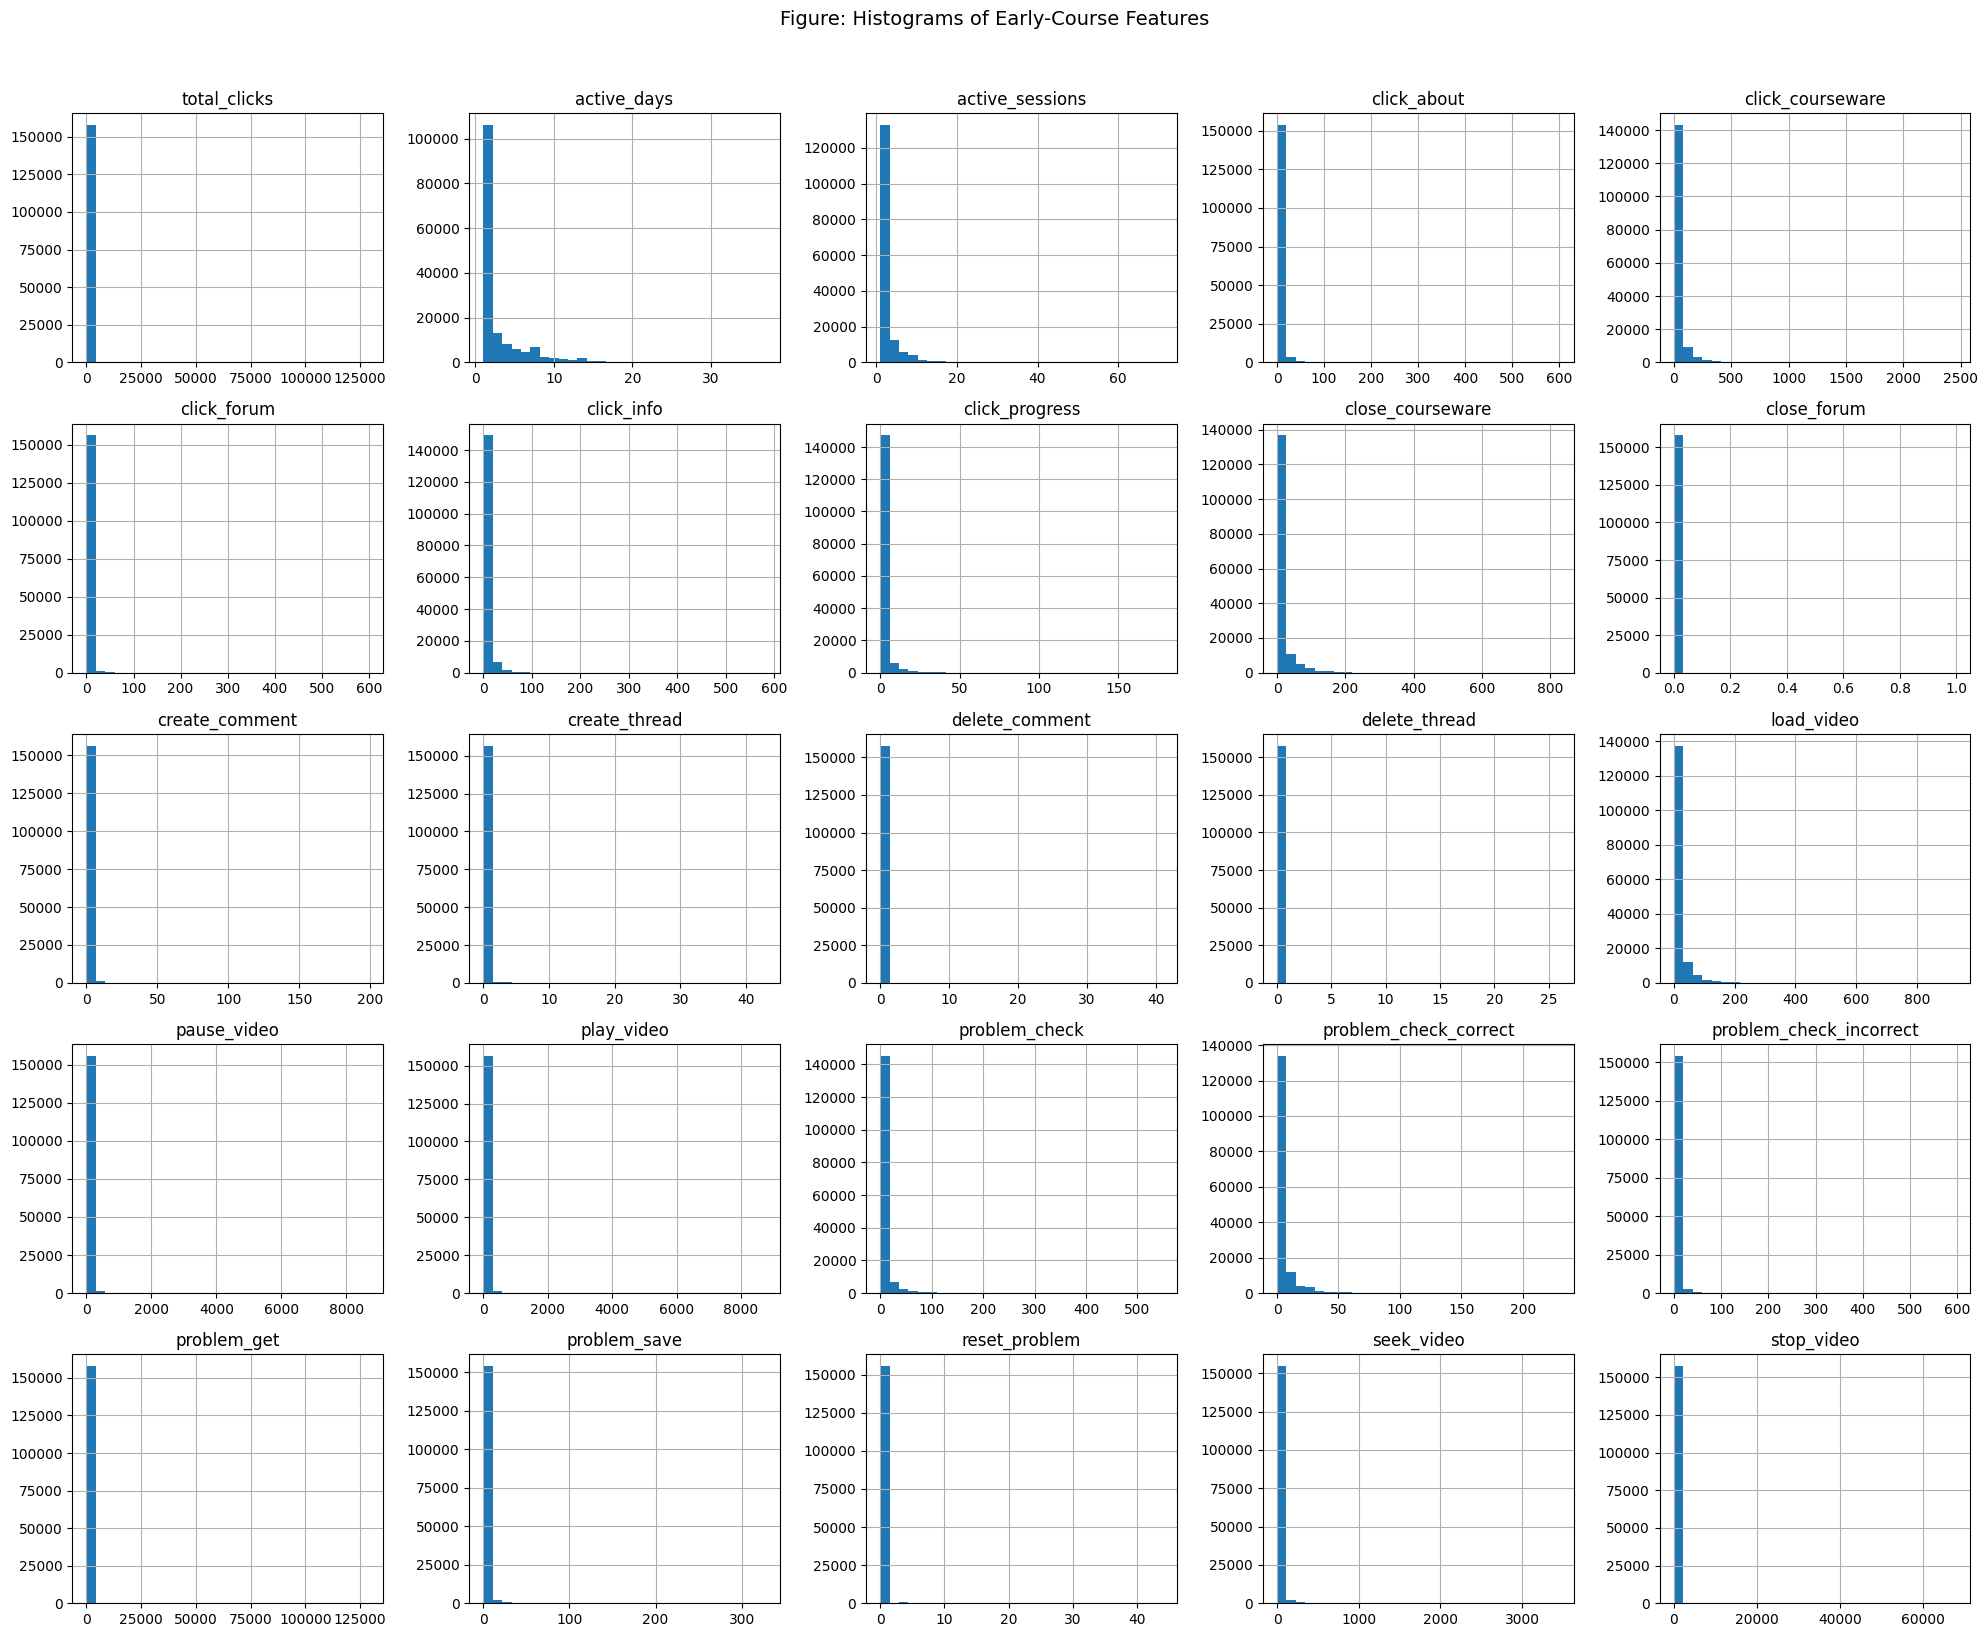

Saved: fig_histograms.png
NOTE: Most engagement count features are expected to be right-skewed (many students with low activity, a few with very high activity). This is typical of behavioral count data and supports the case for scaling in Step 6.

Generating box plots...


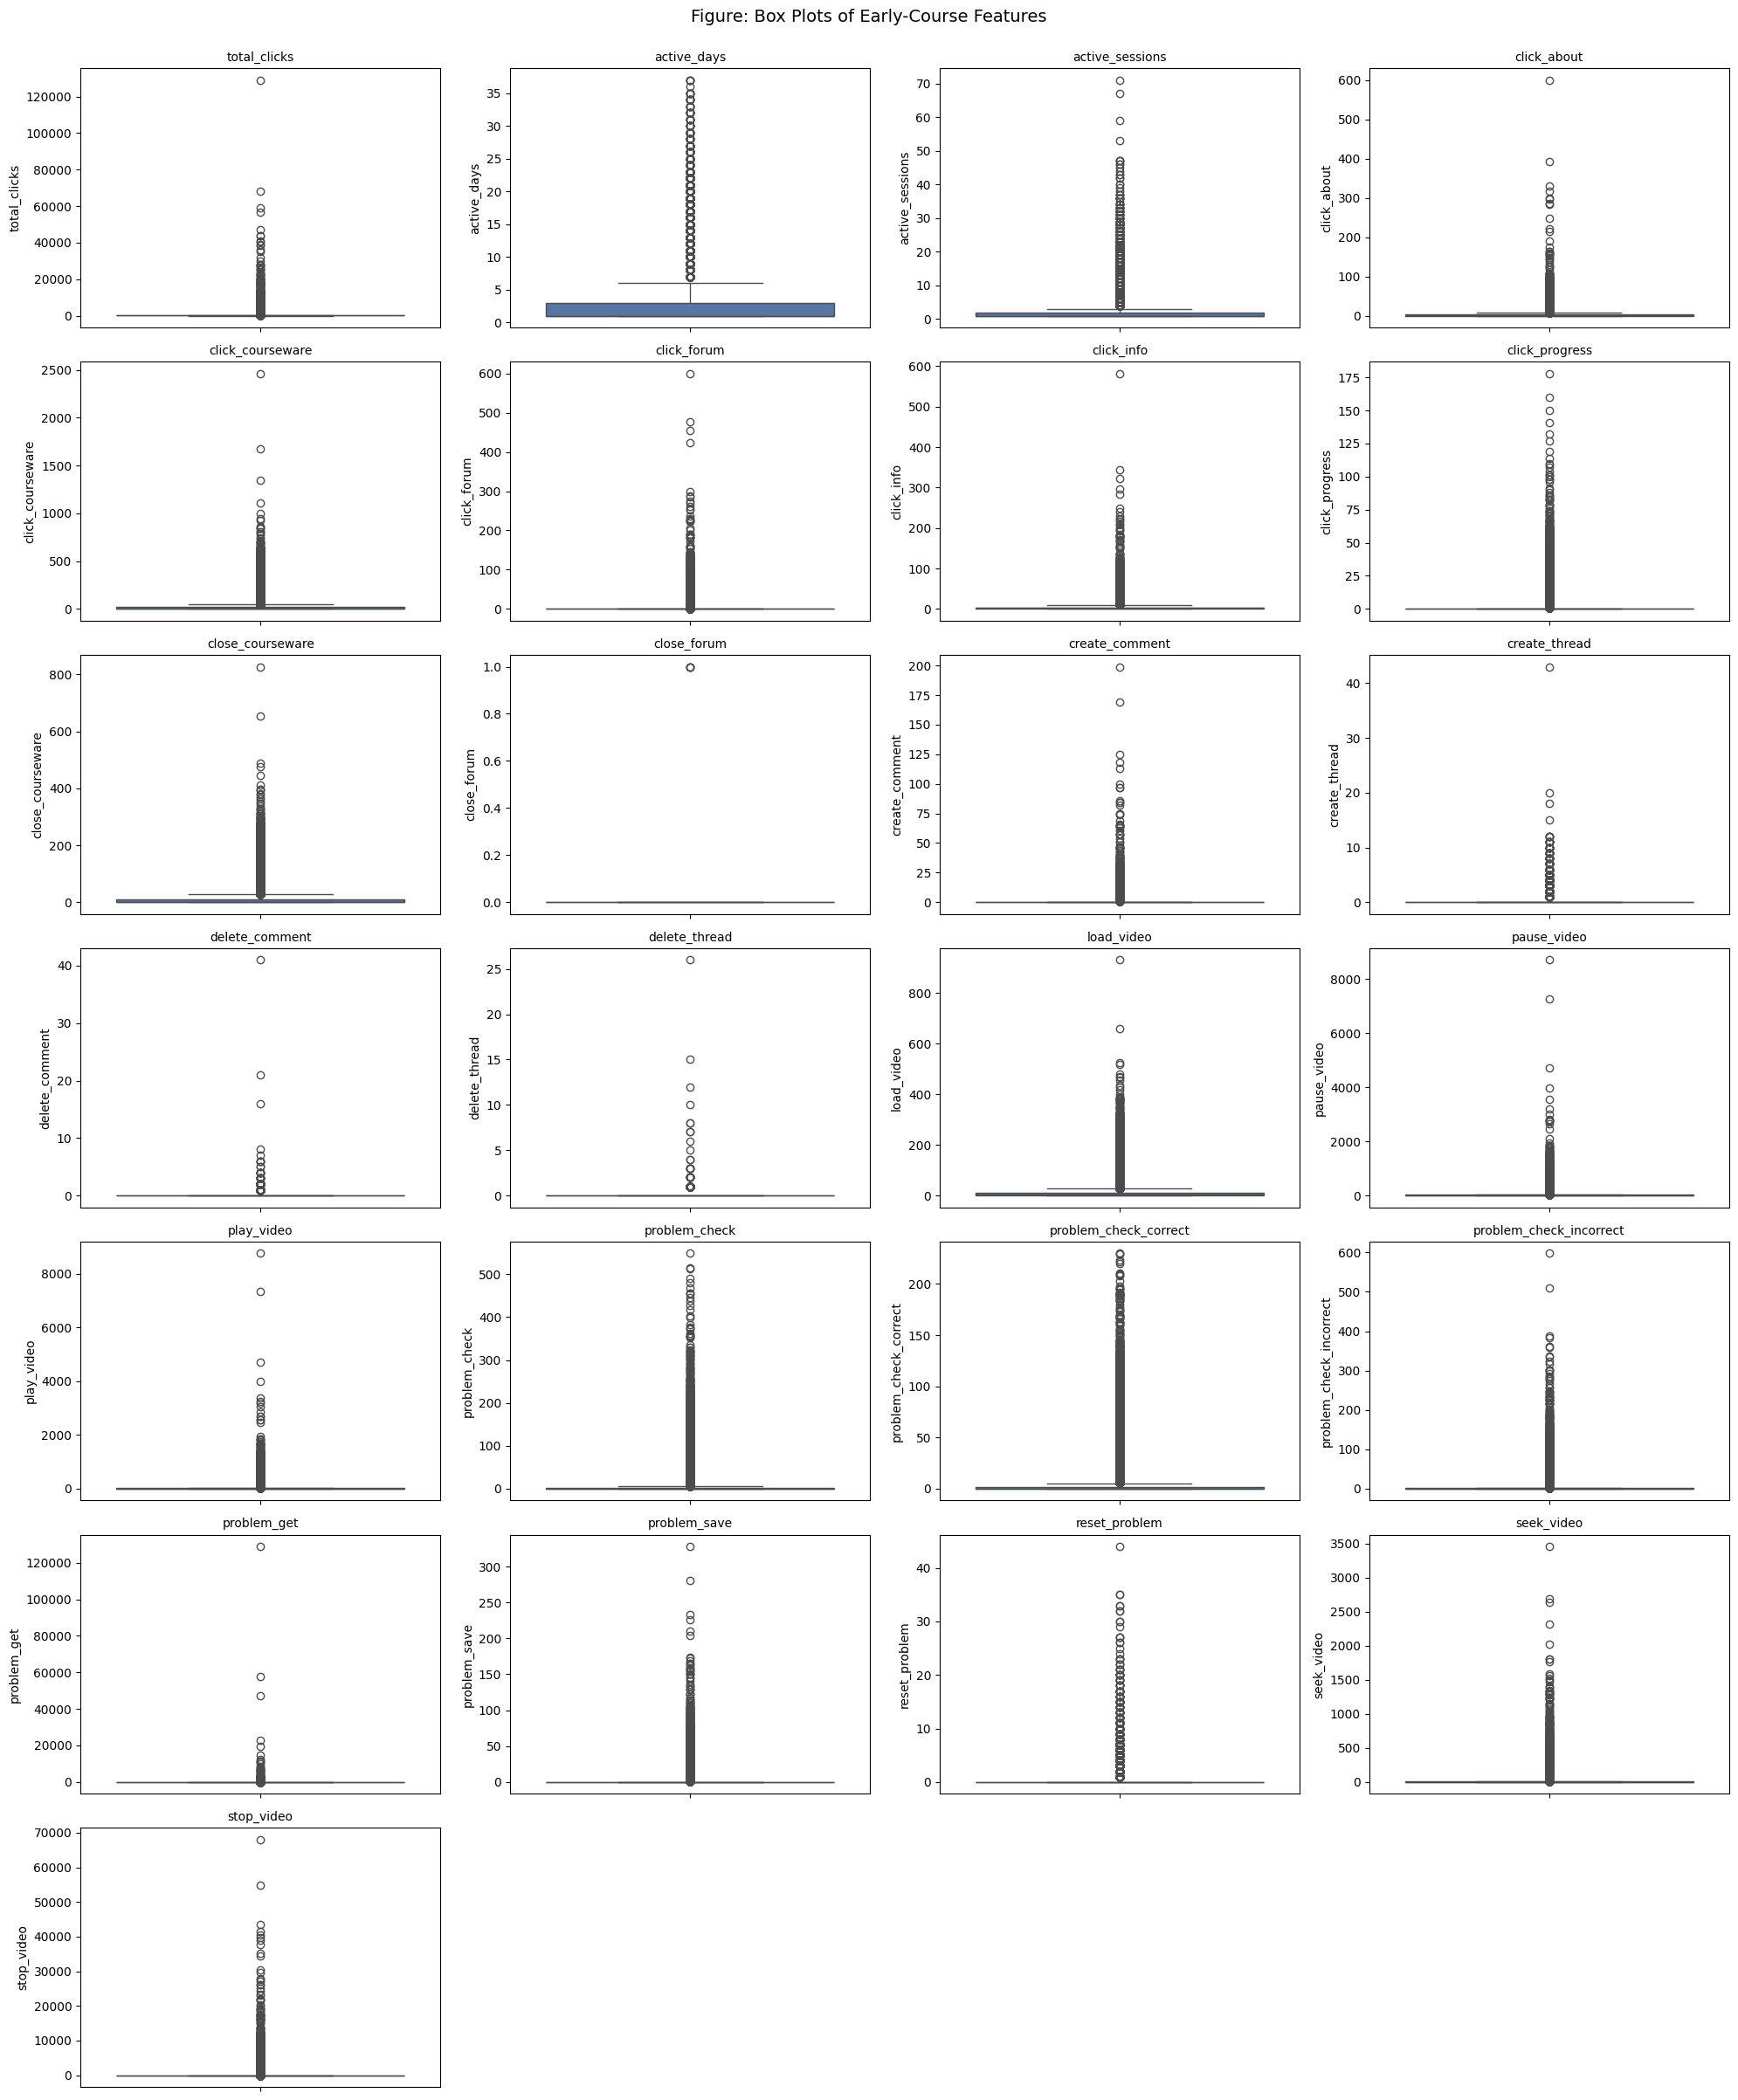

Saved: fig_boxplots.png

Generating correlation matrix...


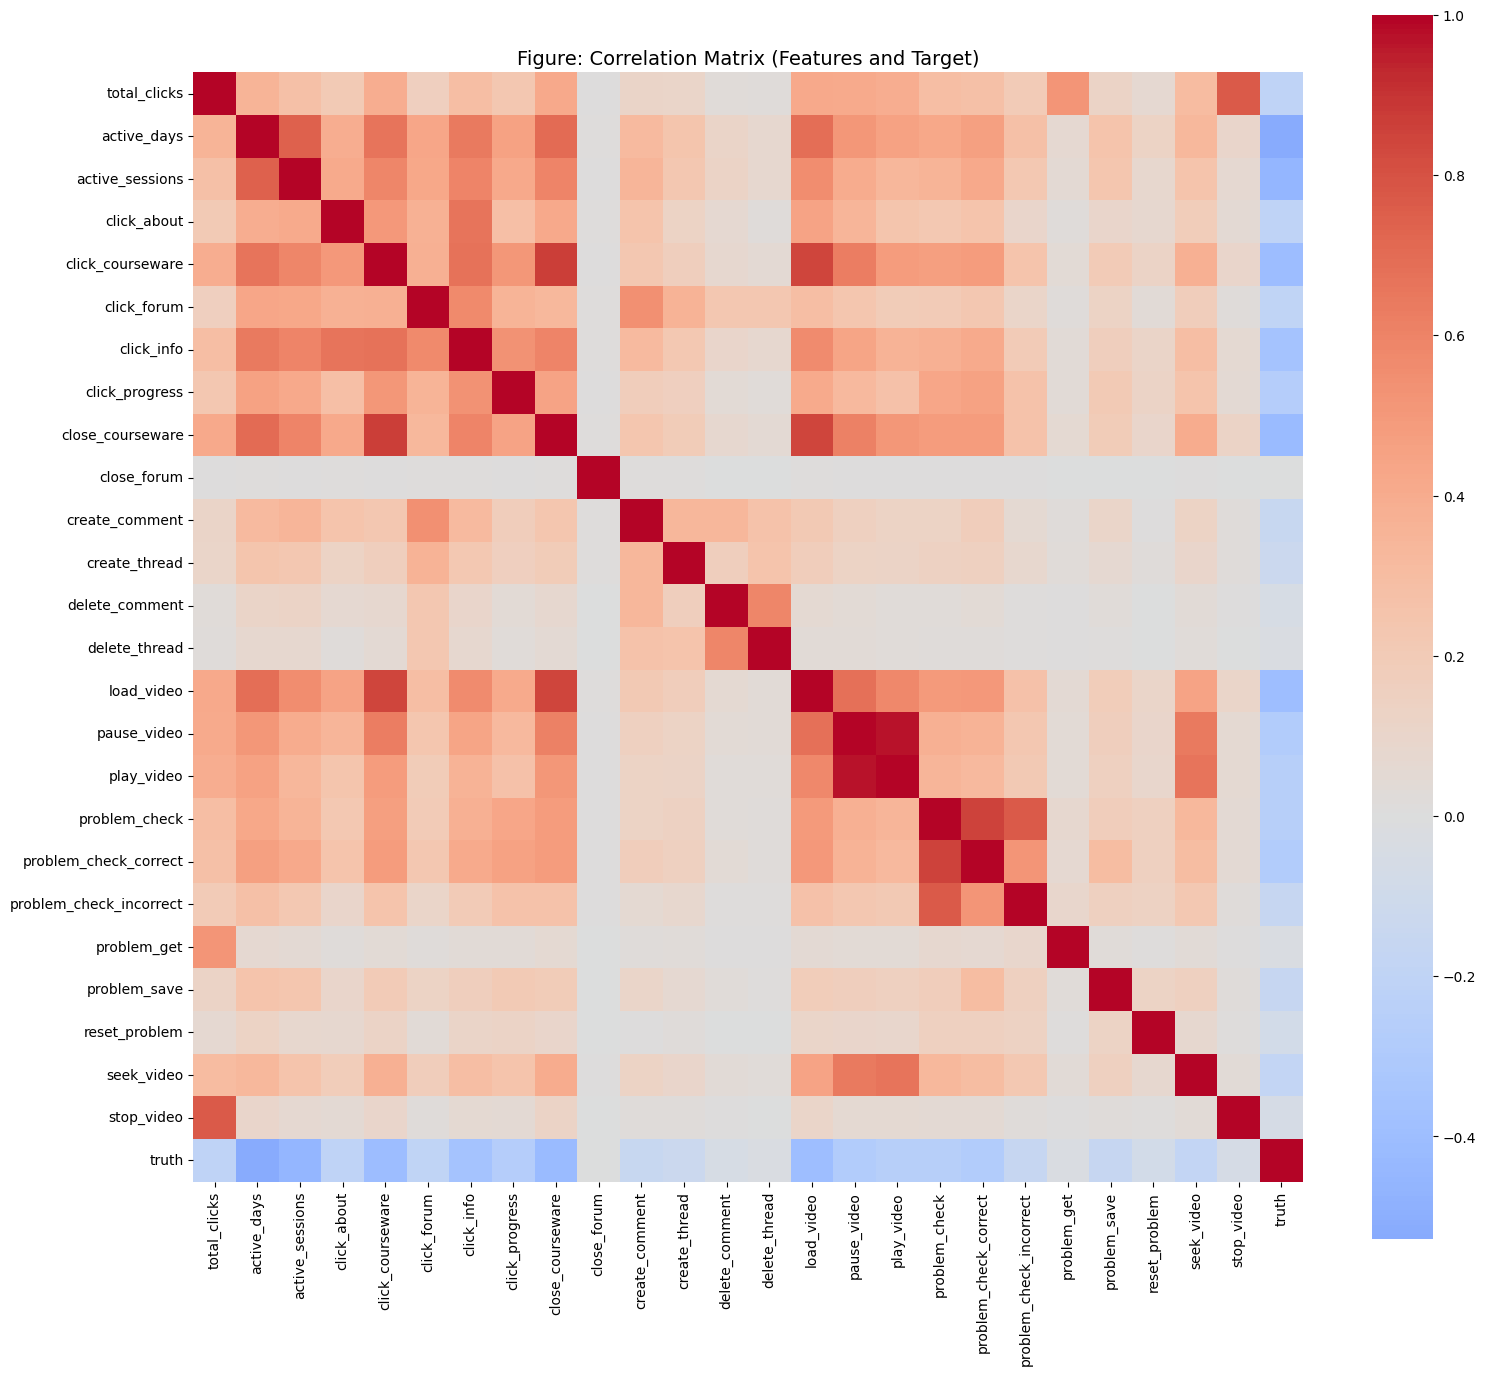

Saved: fig_correlation_matrix.png

--- Features ranked by absolute correlation with 'truth' ---
active_days                0.528104
active_sessions            0.452023
close_courseware           0.421676
click_courseware           0.407444
load_video                 0.399269
click_info                 0.355795
problem_check_correct      0.283133
pause_video                0.282510
click_progress             0.268826
problem_check              0.252121
play_video                 0.250694
click_about                0.211515
total_clicks               0.202319
click_forum                0.196708
seek_video                 0.187692
problem_save               0.161864
problem_check_incorrect    0.156437
create_comment             0.148308
create_thread              0.123652
reset_problem              0.079135
stop_video                 0.058005
delete_comment             0.047942
problem_get                0.031880
delete_thread              0.024847
close_forum                0.003041
Name

In [ ]:
# =============================================================================
# STEP 3: FEATURE SELECTION AND LEAKAGE PREVENTION
# Predicting Student Dropout Risk in Online Learning
# Source: mooc_student_level_cleaned.csv (157,943 students x 27 columns)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif

# -----------------------------------------------------------------------------
# 3a. Load the cleaned dataset
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_student_level_cleaned.csv"
df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("STEP 3: FEATURE SELECTION AND LEAKAGE PREVENTION")
print("=" * 70)
print(f"\nLoaded dataset shape: {df.shape}")

# -----------------------------------------------------------------------------
# 3b. Leakage prevention
# -----------------------------------------------------------------------------
# enroll_id is an identifier, not a predictive feature — exclude it from the
# feature set (but keep it around separately in case we need to trace rows
# back to specific students later).
#
# NOTE: 'problem_check_correct' and 'problem_check_incorrect' are RETAINED
# by deliberate decision (see Step 2 notes) — they represent progressive,
# in-course academic performance signals, not post-hoc outcome information
# like a final grade, and are therefore not treated as leakage here.
# -----------------------------------------------------------------------------

LEAKAGE_OR_ID_COLS = ["enroll_id"]  # identifier only — not a leakage feature

feature_cols = [c for c in df.columns if c not in LEAKAGE_OR_ID_COLS + ["truth"]]
X = df[feature_cols]
y = df["truth"]

print(f"\nFeatures excluded as identifiers: {LEAKAGE_OR_ID_COLS}")
print(f"Number of candidate features going into EDA/selection: {len(feature_cols)}")
print(f"Candidate features: {feature_cols}")

# -----------------------------------------------------------------------------
# 3c. Histograms — distribution shape of each feature
# -----------------------------------------------------------------------------
print("\nGenerating histograms...")
X.hist(bins=30, figsize=(20, 16))
plt.suptitle("Figure: Histograms of Early-Course Features", y=1.02, fontsize=14)
plt.tight_layout()
plt.savefig("/content/fig_histograms.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_histograms.png")
print("NOTE: Most engagement count features are expected to be right-skewed "
      "(many students with low activity, a few with very high activity). "
      "This is typical of behavioral count data and supports the case for "
      "scaling in Step 6.")

# -----------------------------------------------------------------------------
# 3d. Box plots — spread and outliers per feature
# -----------------------------------------------------------------------------
print("\nGenerating box plots...")
fig, axes = plt.subplots(nrows=(len(feature_cols) // 4) + 1, ncols=4, figsize=(20, 24))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    sns.boxplot(y=X[col], ax=axes[i], color="#4C72B0")
    axes[i].set_title(col, fontsize=10)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Figure: Box Plots of Early-Course Features", y=1.0, fontsize=14)
plt.tight_layout()
plt.savefig("/content/fig_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_boxplots.png")

# -----------------------------------------------------------------------------
# 3e. Correlation matrix — feature-target and feature-feature relationships
# -----------------------------------------------------------------------------
print("\nGenerating correlation matrix...")
corr_matrix = df[feature_cols + ["truth"]].corr()

plt.figure(figsize=(16, 14))
sns.heatmap(corr_matrix, annot=False, cmap="coolwarm", center=0, square=True)
plt.title("Figure: Correlation Matrix (Features and Target)", fontsize=14)
plt.tight_layout()
plt.savefig("/content/fig_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_correlation_matrix.png")

# Features most correlated with the target (absolute value)
target_corr = corr_matrix["truth"].drop("truth").abs().sort_values(ascending=False)
print("\n--- Features ranked by absolute correlation with 'truth' ---")
print(target_corr)

CORR_THRESHOLD = 0.05  # behavioral data tends to have weaker individual
                        # correlations than clinical data; threshold set
                        # lower than the cancer-thesis reference (0.3-0.5)
                        # for this reason — document this choice in Ch.3
corr_selected = target_corr[target_corr >= CORR_THRESHOLD].index.tolist()
print(f"\nFeatures meeting correlation threshold (>= {CORR_THRESHOLD}): "
      f"{len(corr_selected)}")
print(corr_selected)

# Multicollinearity flag: feature pairs correlated above 0.85 with each other
print("\n--- Highly correlated feature pairs (possible multicollinearity, |r| > 0.85) ---")
feat_corr = df[feature_cols].corr().abs()
pairs = (
    feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)
high_pairs = pairs[pairs > 0.85]
print(high_pairs if len(high_pairs) > 0 else "None found above 0.85.")

# -----------------------------------------------------------------------------
# 3f. SelectKBest with ANOVA F-test
# -----------------------------------------------------------------------------
print("\n--- SelectKBest with ANOVA F-test ---")
K = 15  # adjustable
anova_selector = SelectKBest(score_func=f_classif, k=K)
anova_selector.fit(X, y)
anova_scores = pd.Series(anova_selector.scores_, index=feature_cols).sort_values(ascending=False)
print(anova_scores)
anova_selected = anova_scores.head(K).index.tolist()
print(f"\nTop {K} features by ANOVA F-test: {anova_selected}")

# -----------------------------------------------------------------------------
# 3g. SelectKBest with Mutual Information
# -----------------------------------------------------------------------------
print("\n--- SelectKBest with Mutual Information ---")
mi_selector = SelectKBest(score_func=lambda X, y: mutual_info_classif(X, y, random_state=42), k=K)
mi_selector.fit(X, y)
mi_scores = pd.Series(mi_selector.scores_, index=feature_cols).sort_values(ascending=False)
print(mi_scores)
mi_selected = mi_scores.head(K).index.tolist()
print(f"\nTop {K} features by Mutual Information: {mi_selected}")

# -----------------------------------------------------------------------------
# 3h. Combined relevant features
#     Union of: correlation threshold, top-K ANOVA, top-K Mutual Information
# -----------------------------------------------------------------------------
combined_features = sorted(set(corr_selected) | set(anova_selected) | set(mi_selected))
print("\n" + "=" * 70)
print(f"COMBINED RELEVANT FEATURES (union of all 3 methods): {len(combined_features)}")
print("=" * 70)
print(combined_features)

# -----------------------------------------------------------------------------
# 3i. Save the final selected feature set
# -----------------------------------------------------------------------------
final_df = df[["enroll_id"] + combined_features + ["truth"]]
SELECTED_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_selected_features.csv"
final_df.to_csv(SELECTED_PATH, index=False)

print(f"\nFinal selected-feature dataset saved to: {SELECTED_PATH}")
print(f"Final shape: {final_df.shape}")
print("\nSTEP 3 COMPLETE — ready for Step 4: Class Imbalance Handling")

In [ ]:
!pip install imbalanced-learn -q


Mounted at /content/drive
STEP 4: CLASS IMBALANCE HANDLING

Loaded dataset shape: (157943, 24)

Number of features: 22
Features: ['active_days', 'active_sessions', 'click_about', 'click_courseware', 'click_forum', 'click_info', 'click_progress', 'close_courseware', 'create_comment', 'create_thread', 'load_video', 'pause_video', 'play_video', 'problem_check', 'problem_check_correct', 'problem_check_incorrect', 'problem_get', 'problem_save', 'reset_problem', 'seek_video', 'stop_video', 'total_clicks']

--- Class distribution BEFORE balancing ---
  Dropped out (1): 119,817  (75.9%)
  Completed   (0): 38,126  (24.1%)
  Imbalance ratio: 3.14 : 1

--- Class distribution AFTER RandomUnderSampling ---
  Dropped out (1): 38,126  (50.0%)
  Completed   (0): 38,126  (50.0%)
  Total samples remaining: 76,252
  Samples removed from majority class: 81,691


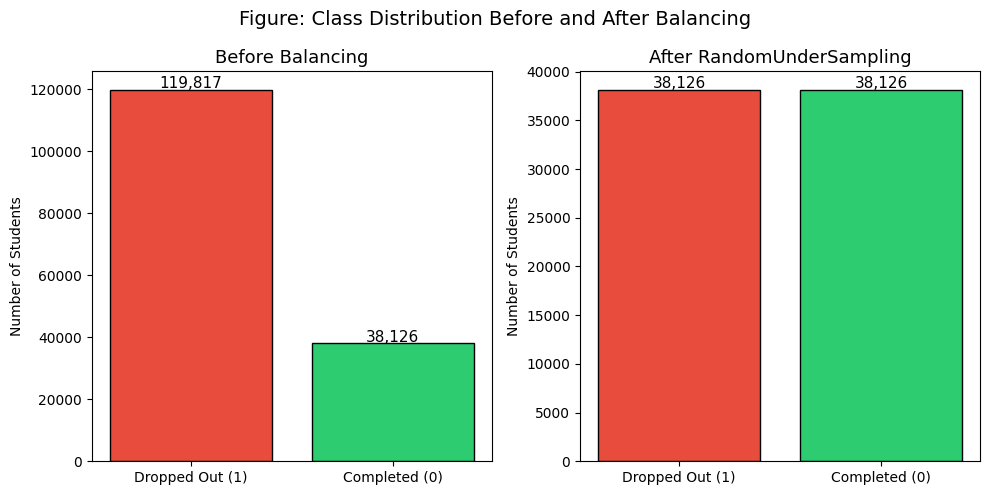

Saved: fig_class_balance.png

Balanced dataset saved to: /content/drive/MyDrive/MOOC_Thesis_Data/mooc_balanced.csv
Final shape: (76252, 23)

STEP 4 COMPLETE — ready for Step 5: Data Splitting


In [ ]:
# =============================================================================
# STEP 4: CLASS IMBALANCE HANDLING
# Predicting Student Dropout Risk in Online Learning
# Source: mooc_selected_features.csv (157,943 students x 24 columns)
# Goal: Balance the dropout (1) vs completed (0) classes in the TRAINING data
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from imblearn.under_sampling import RandomUnderSampler

# -----------------------------------------------------------------------------
# 4a. Load the selected-feature dataset from Google Drive
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_selected_features.csv"
df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("STEP 4: CLASS IMBALANCE HANDLING")
print("=" * 70)
print(f"\nLoaded dataset shape: {df.shape}")

# -----------------------------------------------------------------------------
# 4b. Separate features (X) and target (y)
#     enroll_id is an identifier — excluded from features
# -----------------------------------------------------------------------------
feature_cols = [c for c in df.columns if c not in ["enroll_id", "truth"]]
X = df[feature_cols]
y = df["truth"]

print(f"\nNumber of features: {len(feature_cols)}")
print(f"Features: {feature_cols}")

# -----------------------------------------------------------------------------
# 4c. Class distribution BEFORE balancing
# -----------------------------------------------------------------------------
before_counts = Counter(y)
print("\n--- Class distribution BEFORE balancing ---")
print(f"  Dropped out (1): {before_counts[1]:,}  ({before_counts[1]/len(y)*100:.1f}%)")
print(f"  Completed   (0): {before_counts[0]:,}  ({before_counts[0]/len(y)*100:.1f}%)")
print(f"  Imbalance ratio: {before_counts[1]/before_counts[0]:.2f} : 1")

# -----------------------------------------------------------------------------
# 4d. Apply RandomUnderSampler
#     This removes random rows from the MAJORITY class (dropped out = 1)
#     until both classes are equal in size.
#     random_state=42 ensures the same rows are removed every time you run
#     this, making your results reproducible.
# -----------------------------------------------------------------------------
rus = RandomUnderSampler(random_state=42)
X_balanced, y_balanced = rus.fit_resample(X, y)

# -----------------------------------------------------------------------------
# 4e. Class distribution AFTER balancing
# -----------------------------------------------------------------------------
after_counts = Counter(y_balanced)
print("\n--- Class distribution AFTER RandomUnderSampling ---")
print(f"  Dropped out (1): {after_counts[1]:,}  ({after_counts[1]/len(y_balanced)*100:.1f}%)")
print(f"  Completed   (0): {after_counts[0]:,}  ({after_counts[0]/len(y_balanced)*100:.1f}%)")
print(f"  Total samples remaining: {len(y_balanced):,}")
print(f"  Samples removed from majority class: {before_counts[1] - after_counts[1]:,}")

# -----------------------------------------------------------------------------
# 4f. Bar chart comparing class distribution before and after
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Before
axes[0].bar(["Dropped Out (1)", "Completed (0)"],
            [before_counts[1], before_counts[0]],
            color=["#E74C3C", "#2ECC71"], edgecolor="black")
axes[0].set_title("Before Balancing", fontsize=13)
axes[0].set_ylabel("Number of Students")
for i, v in enumerate([before_counts[1], before_counts[0]]):
    axes[0].text(i, v + 500, f"{v:,}", ha="center", fontsize=11)

# After
axes[1].bar(["Dropped Out (1)", "Completed (0)"],
            [after_counts[1], after_counts[0]],
            color=["#E74C3C", "#2ECC71"], edgecolor="black")
axes[1].set_title("After RandomUnderSampling", fontsize=13)
axes[1].set_ylabel("Number of Students")
for i, v in enumerate([after_counts[1], after_counts[0]]):
    axes[1].text(i, v + 200, f"{v:,}", ha="center", fontsize=11)

plt.suptitle("Figure: Class Distribution Before and After Balancing", fontsize=14)
plt.tight_layout()
plt.savefig("/content/fig_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_class_balance.png")

# -----------------------------------------------------------------------------
# 4g. Save the balanced dataset
# -----------------------------------------------------------------------------
balanced_df = pd.DataFrame(X_balanced, columns=feature_cols)
balanced_df["truth"] = y_balanced.values

BALANCED_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_balanced.csv"
balanced_df.to_csv(BALANCED_PATH, index=False)

print(f"\nBalanced dataset saved to: {BALANCED_PATH}")
print(f"Final shape: {balanced_df.shape}")
print("\nSTEP 4 COMPLETE — ready for Step 5: Data Splitting")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 5: DATA SPLITTING

Loaded balanced dataset shape: (76252, 23)

Features (X): ['active_days', 'active_sessions', 'click_about', 'click_courseware', 'click_forum', 'click_info', 'click_progress', 'close_courseware', 'create_comment', 'create_thread', 'load_video', 'pause_video', 'play_video', 'problem_check', 'problem_check_correct', 'problem_check_incorrect', 'problem_get', 'problem_save', 'reset_problem', 'seek_video', 'stop_video', 'total_clicks']

Target (y): 'truth'  |  Unique values: [np.int64(0), np.int64(1)]

--- Split sizes ---
  Training set:  61,001 students (80.0%)
  Test set:      15,251 students  (20.0%)
  Total:         76,252 students

--- Class distribution in TRAINING set ---
  Dropped out (1): 30,501  (50.0%)
  Completed   (0): 30,500  (50.0%)

--- Class distribution in TEST set ---
  Dropped out (1): 7,625  (50.0%)
  Completed   (0): 7,

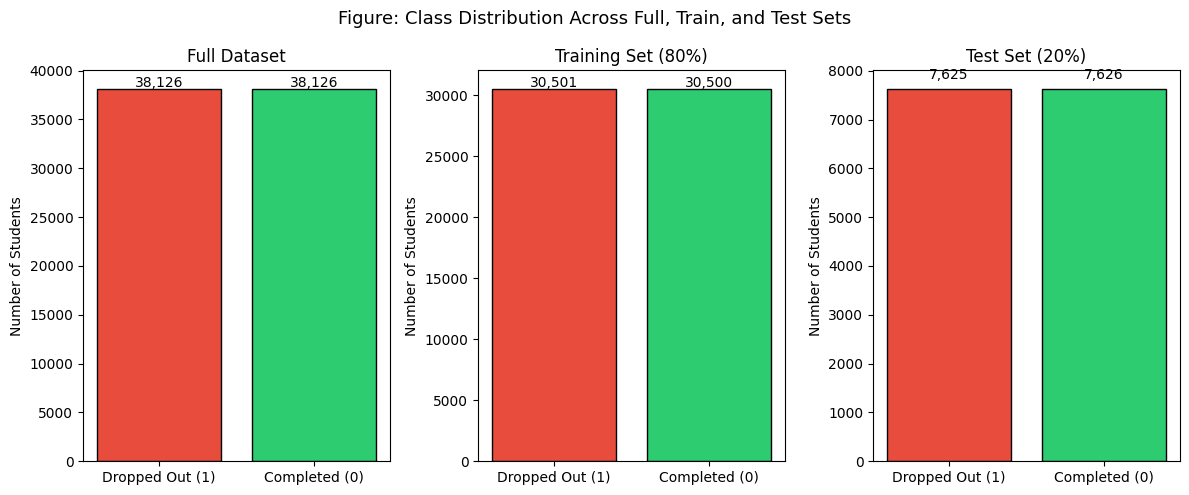

Saved: fig_data_split.png

Training set saved to: /content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv
Test set saved to:     /content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv

Training set shape: (61001, 22)
Test set shape:     (15251, 22)

STEP 5 COMPLETE — ready for Step 6: Feature Scaling


In [ ]:
# =============================================================================
# STEP 5: DATA SPLITTING
# Predicting Student Dropout Risk in Online Learning
# Source: mooc_balanced.csv (76,252 students x 23 columns)
# Goal: Split into 80% training set and 20% test set using stratified sampling
# =============================================================================

import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# 5a. Load the balanced dataset from Google Drive
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

DATA_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/mooc_balanced.csv"
df = pd.read_csv(DATA_PATH)

print("=" * 70)
print("STEP 5: DATA SPLITTING")
print("=" * 70)
print(f"\nLoaded balanced dataset shape: {df.shape}")

# -----------------------------------------------------------------------------
# 5b. Separate features (X) and target (y)
# -----------------------------------------------------------------------------
feature_cols = [c for c in df.columns if c != "truth"]
X = df[feature_cols]
y = df["truth"]

print(f"\nFeatures (X): {list(X.columns)}")
print(f"\nTarget (y): 'truth'  |  Unique values: {sorted(y.unique())}")

# -----------------------------------------------------------------------------
# 5c. Perform the train-test split
#
# WHY 80/20?
# This is a widely used split ratio — it gives the model enough data to learn
# patterns (80%) while keeping a large enough holdout (20%) for a reliable,
# unbiased evaluation of how the model performs on unseen students.
#
# WHY stratify=y?
# Even though our dataset is now balanced (50/50 after Step 4), stratification
# is still best practice — it guarantees that the exact same class proportion
# is maintained in both the training and test sets, preventing any accidental
# skew that could arise from random sampling alone.
#
# WHY random_state=42?
# Fixes the random seed so that the exact same split is produced every time
# this code is run, making results fully reproducible.
# -----------------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# -----------------------------------------------------------------------------
# 5d. Confirm the split sizes and class distributions
# -----------------------------------------------------------------------------
print("\n--- Split sizes ---")
print(f"  Training set:  {X_train.shape[0]:,} students ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"  Test set:      {X_test.shape[0]:,} students  ({X_test.shape[0]/len(df)*100:.1f}%)")
print(f"  Total:         {len(df):,} students")

print("\n--- Class distribution in TRAINING set ---")
train_counts = y_train.value_counts()
print(f"  Dropped out (1): {train_counts[1]:,}  ({train_counts[1]/len(y_train)*100:.1f}%)")
print(f"  Completed   (0): {train_counts[0]:,}  ({train_counts[0]/len(y_train)*100:.1f}%)")

print("\n--- Class distribution in TEST set ---")
test_counts = y_test.value_counts()
print(f"  Dropped out (1): {test_counts[1]:,}  ({test_counts[1]/len(y_test)*100:.1f}%)")
print(f"  Completed   (0): {test_counts[0]:,}  ({test_counts[0]/len(y_test)*100:.1f}%)")

# -----------------------------------------------------------------------------
# 5e. Bar chart showing the split
# -----------------------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

sets    = ["Full Dataset", "Training Set (80%)", "Test Set (20%)"]
counts  = [
    [y.value_counts()[1], y.value_counts()[0]],
    [train_counts[1], train_counts[0]],
    [test_counts[1], test_counts[0]],
]
colors  = ["#E74C3C", "#2ECC71"]
labels  = ["Dropped Out (1)", "Completed (0)"]

for i, ax in enumerate(axes):
    bars = ax.bar(labels, counts[i], color=colors, edgecolor="black")
    ax.set_title(sets[i], fontsize=12)
    ax.set_ylabel("Number of Students")
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 200,
                f"{int(bar.get_height()):,}",
                ha="center", fontsize=10)

plt.suptitle("Figure: Class Distribution Across Full, Train, and Test Sets",
             fontsize=13)
plt.tight_layout()
plt.savefig("/content/fig_data_split.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_data_split.png")

# -----------------------------------------------------------------------------
# 5f. Save train and test sets to Google Drive
# -----------------------------------------------------------------------------
TRAIN_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv"
TEST_PATH  = "/content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv"

X_train_save = X_train.copy()
X_train_save["truth"] = y_train.values
X_train_save.to_csv(TRAIN_PATH, index=False)

X_test_save = X_test.copy()
X_test_save["truth"] = y_test.values
X_test_save.to_csv(TEST_PATH, index=False)

print(f"\nTraining set saved to: {TRAIN_PATH}")
print(f"Test set saved to:     {TEST_PATH}")
print(f"\nTraining set shape: {X_train.shape}")
print(f"Test set shape:     {X_test.shape}")
print("\nSTEP 5 COMPLETE — ready for Step 6: Feature Scaling")

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from google.colab import drive
drive.mount('/content/drive')

# Load train and test sets
train = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv")
test  = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv")

feature_cols = [c for c in train.columns if c != "truth"]

X_train = train[feature_cols]
y_train = train["truth"]
X_test  = test[feature_cols]
y_test  = test["truth"]

# Fit ONLY on training data, then transform both
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("=" * 70)
print("STEP 6: FEATURE SCALING")
print("=" * 70)
print(f"\nTraining set scaled shape: {X_train_scaled.shape}")
print(f"Test set scaled shape:     {X_test_scaled.shape}")
print(f"\nSample means after scaling (should be ~0.0):")
print(pd.DataFrame(X_train_scaled, columns=feature_cols).mean().round(4))
print(f"\nSample std after scaling (should be ~1.0):")
print(pd.DataFrame(X_train_scaled, columns=feature_cols).std().round(4))
print("\nSTEP 6 COMPLETE — ready for Step 7: Model Training")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 6: FEATURE SCALING

Training set scaled shape: (61001, 22)
Test set scaled shape:     (15251, 22)

Sample means after scaling (should be ~0.0):
active_days                0.0
active_sessions            0.0
click_about               -0.0
click_courseware           0.0
click_forum               -0.0
click_info                -0.0
click_progress            -0.0
close_courseware          -0.0
create_comment             0.0
create_thread             -0.0
load_video                 0.0
pause_video               -0.0
play_video                -0.0
problem_check             -0.0
problem_check_correct     -0.0
problem_check_incorrect   -0.0
problem_get               -0.0
problem_save              -0.0
reset_problem             -0.0
seek_video                 0.0
stop_video                -0.0
total_clicks              -0.0
dtype: float64

Sample std after scaling

In [ ]:
!pip install xgboost -q
print("XGBoost ready.")

XGBoost ready.


In [ ]:
# =============================================================================
# STEP 7: MODEL TRAINING — SIMPLIFIED, UNIFIED PARAMETERS
# Predicting Student Dropout Risk in Online Learning
# Thabisile Moloi | 202103142 | Supervisor: Dr VR Baloyi
#
# PARAMETER PHILOSOPHY (per Dr Baloyi's feedback: keep it minimal):
#   random_state = 42  → ALL models. Not a tuning choice — fixed purely for
#                         reproducibility, so it isn't counted as a
#                         "hyperparameter" being tuned.
#   n_estimators = 200 → RF and XGBoost use the SAME value, fixed once, so
#                         the two tree-based models are directly comparable.
#   max_depth           → left at each library's default (not manually set),
#                         so it isn't another parameter to justify.
#   learning_rate        → the ONE parameter that is actually tuned. It only
#                         applies to XGBoost (RF and Logistic Regression have
#                         no learning_rate — RF averages independent trees,
#                         LR solves directly, neither takes gradient steps).
#                         A small comparison below tests a few candidate
#                         values and selects the best-performing one.
# =============================================================================

import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)
import warnings
warnings.filterwarnings("ignore")

# -----------------------------------------------------------------------------
# Load train and test sets from Google Drive
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv")
test  = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv")

feature_cols = [c for c in train.columns if c != "truth"]

X_train = train[feature_cols]
y_train = train["truth"]
X_test  = test[feature_cols]
y_test  = test["truth"]

# Re-apply feature scaling (fit on train only)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print("=" * 70)
print("STEP 7: MODEL TRAINING (UNIFIED PARAMETERS)")
print("=" * 70)
print(f"\nTraining set: {X_train_scaled.shape[0]:,} students, {X_train_scaled.shape[1]} features")
print(f"Test set:     {X_test_scaled.shape[0]:,} students, {X_test_scaled.shape[1]} features")
print(f"\nFixed parameters (not tuned):")
print(f"  random_state = 42  (all models, for reproducibility)")
print(f"  n_estimators = 200 (RF and XGBoost — same value, for fair comparison)")

# 5-fold StratifiedKFold — used for CV scoring AND inside the stacking ensemble
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# -----------------------------------------------------------------------------
# LEARNING RATE COMPARISON (XGBoost's one tuned parameter)
# n_estimators and random_state are held fixed (see header). We only vary
# learning_rate here and compare ROC AUC on the test set, to justify the
# final choice used for the rest of Step 7 and all later steps.
# -----------------------------------------------------------------------------
print("\n" + "=" * 70)
print("LEARNING RATE COMPARISON (XGBoost)")
print("=" * 70)

candidate_rates = [0.01, 0.05, 0.1, 0.2, 0.3]
lr_comparison_results = []

for rate in candidate_rates:
    candidate_xgb = XGBClassifier(
        n_estimators=200,
        learning_rate=rate,
        random_state=42,
        eval_metric="logloss",
        verbosity=0
    )
    candidate_xgb.fit(X_train_scaled, y_train)
    candidate_proba = candidate_xgb.predict_proba(X_test_scaled)[:, 1]
    candidate_auc = roc_auc_score(y_test, candidate_proba)
    lr_comparison_results.append({"learning_rate": rate, "ROC AUC": round(candidate_auc * 100, 2)})
    print(f"  learning_rate = {rate:<5} -> ROC AUC = {candidate_auc * 100:.2f}%")

lr_comparison_df = pd.DataFrame(lr_comparison_results)
best_rate_row = lr_comparison_df.loc[lr_comparison_df["ROC AUC"].idxmax()]
BEST_LEARNING_RATE = best_rate_row["learning_rate"]

print(f"\nBest learning_rate: {BEST_LEARNING_RATE} (ROC AUC = {best_rate_row['ROC AUC']}%)")
print("This value is used for XGBoost for the remainder of Step 7 and in Steps 8-9.")

LR_COMPARISON_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/learning_rate_comparison.csv"
lr_comparison_df.to_csv(LR_COMPARISON_PATH, index=False)
print(f"Saved learning rate comparison to: {LR_COMPARISON_PATH}")

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    results = {
        "Model":     name,
        "Accuracy":  round(accuracy_score(y_te, y_pred)  * 100, 2),
        "Precision": round(precision_score(y_te, y_pred) * 100, 2),
        "Recall":    round(recall_score(y_te, y_pred)    * 100, 2),
        "F1":        round(f1_score(y_te, y_pred)        * 100, 2),
        "ROC AUC":   round(roc_auc_score(y_te, y_proba)  * 100, 2),
    }
    cv_scores = cross_val_score(model, X_tr, y_tr, cv=cv, scoring="f1")
    results["CV F1 (mean)"] = round(cv_scores.mean() * 100, 2)
    results["CV F1 (std)"]  = round(cv_scores.std()  * 100, 2)
    return results, model

all_results = []

# ── Base Learner 1: Logistic Regression ──────────────────────────────────────
print("\n--- Training Base Learner 1: Logistic Regression ---")
lr = LogisticRegression(max_iter=1000, random_state=42)
lr_results, lr_model = evaluate_model(
    "Logistic Regression", lr,
    X_train_scaled, y_train, X_test_scaled, y_test
)
all_results.append(lr_results)
print(f"  Accuracy:  {lr_results['Accuracy']}%")
print(f"  F1 Score:  {lr_results['F1']}%")
print(f"  ROC AUC:   {lr_results['ROC AUC']}%")
print(f"  CV F1:     {lr_results['CV F1 (mean)']}% ± {lr_results['CV F1 (std)']}%")

# ── Base Learner 2: Random Forest ─────────────────────────────────────────────
# CHANGED: n_estimators=250 → n_estimators=200 (same as XGBoost)
print("\n--- Training Base Learner 2: Random Forest (n_estimators=200) ---")
rf = RandomForestClassifier(
    n_estimators=200,   # ← CHANGED from 250 to 200 (matches XGBoost)
    random_state=42,
    n_jobs=-1
)
rf_results, rf_model = evaluate_model(
    "Random Forest", rf,
    X_train_scaled, y_train, X_test_scaled, y_test
)
all_results.append(rf_results)
print(f"  Accuracy:  {rf_results['Accuracy']}%")
print(f"  F1 Score:  {rf_results['F1']}%")
print(f"  ROC AUC:   {rf_results['ROC AUC']}%")
print(f"  CV F1:     {rf_results['CV F1 (mean)']}% ± {rf_results['CV F1 (std)']}%")

# ── Base Learner 3: XGBoost ───────────────────────────────────────────────────
print("\n--- Training Base Learner 3: XGBoost (n_estimators=200, lr=0.1) ---")
xgb = XGBClassifier(
    n_estimators=200,           # same as RF
    learning_rate=BEST_LEARNING_RATE,  # selected above via comparison
    random_state=42,
    eval_metric="logloss",
    verbosity=0
)
xgb_results, xgb_model = evaluate_model(
    "XGBoost", xgb,
    X_train_scaled, y_train, X_test_scaled, y_test
)
all_results.append(xgb_results)
print(f"  Accuracy:  {xgb_results['Accuracy']}%")
print(f"  F1 Score:  {xgb_results['F1']}%")
print(f"  ROC AUC:   {xgb_results['ROC AUC']}%")
print(f"  CV F1:     {xgb_results['CV F1 (mean)']}% ± {xgb_results['CV F1 (std)']}%")

# ── Stacked Ensemble ──────────────────────────────────────────────────────────
# HOW 5-FOLD CV WORKS IN STACKING:
#   For each of the 5 folds, the base learners train on 4 folds and predict
#   on the held-out 5th fold. Every training student gets a prediction from
#   a model that never saw them ("out-of-fold predictions"). The meta-learner
#   trains on these clean, leakage-free predictions.
#
# passthrough=False: only base learner predictions go to the meta-learner
# (cleaner and more interpretable than passthrough=True)
print("\n--- Training Stacked Ensemble (Meta-Learner: Logistic Regression) ---")
print("    (5-fold CV generates out-of-fold predictions to prevent leakage)")

base_learners = [
    ("lr",  LogisticRegression(max_iter=1000, random_state=42)),
    ("rf",  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),  # 200
    ("xgb", XGBClassifier(n_estimators=200, learning_rate=BEST_LEARNING_RATE,
                          random_state=42, eval_metric="logloss", verbosity=0)),
]

stacking = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=cv,              # 5-fold StratifiedKFold
    passthrough=False,  # only base learner predictions to meta-learner
    n_jobs=-1
)

stacking_results, stacking_model = evaluate_model(
    "Stacked Ensemble", stacking,
    X_train_scaled, y_train, X_test_scaled, y_test
)
all_results.append(stacking_results)
print(f"  Accuracy:  {stacking_results['Accuracy']}%")
print(f"  F1 Score:  {stacking_results['F1']}%")
print(f"  ROC AUC:   {stacking_results['ROC AUC']}%")
print(f"  CV F1:     {stacking_results['CV F1 (mean)']}% ± {stacking_results['CV F1 (std)']}%")

# Summary table
print("\n" + "=" * 70)
print("MODEL COMPARISON SUMMARY (UNIFIED PARAMETERS)")
print("=" * 70)
results_df = pd.DataFrame(all_results).set_index("Model")
print(results_df.to_string())

# Save updated results
RESULTS_PATH = "/content/drive/MyDrive/MOOC_Thesis_Data/model_results.csv"
results_df.to_csv(RESULTS_PATH)
print(f"\nUpdated results saved to: {RESULTS_PATH}")
print("\nSTEP 7 COMPLETE — proceed to Step 8 (rerun evaluation plots)")

Mounted at /content/drive
STEP 7: MODEL TRAINING (UNIFIED PARAMETERS)

Training set: 61,001 students, 22 features
Test set:     15,251 students, 22 features

Fixed parameters (not tuned):
  random_state = 42  (all models, for reproducibility)
  n_estimators = 200 (RF and XGBoost — same value, for fair comparison)

LEARNING RATE COMPARISON (XGBoost)
  learning_rate = 0.01  -> ROC AUC = 84.59%
  learning_rate = 0.05  -> ROC AUC = 84.86%
  learning_rate = 0.1   -> ROC AUC = 84.85%
  learning_rate = 0.2   -> ROC AUC = 84.56%
  learning_rate = 0.3   -> ROC AUC = 84.13%

Best learning_rate: 0.05 (ROC AUC = 84.86%)
This value is used for XGBoost for the remainder of Step 7 and in Steps 8-9.
Saved learning rate comparison to: /content/drive/MyDrive/MOOC_Thesis_Data/learning_rate_comparison.csv

--- Training Base Learner 1: Logistic Regression ---
  Accuracy:  76.41%
  F1 Score:  78.79%
  ROC AUC:   83.02%
  CV F1:     78.67% ± 0.41%

--- Training Base Learner 2: Random Forest (n_estimators=200

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 8: MODEL EVALUATION

Re-training models for evaluation plots...
All models re-trained.

Generating confusion matrices...


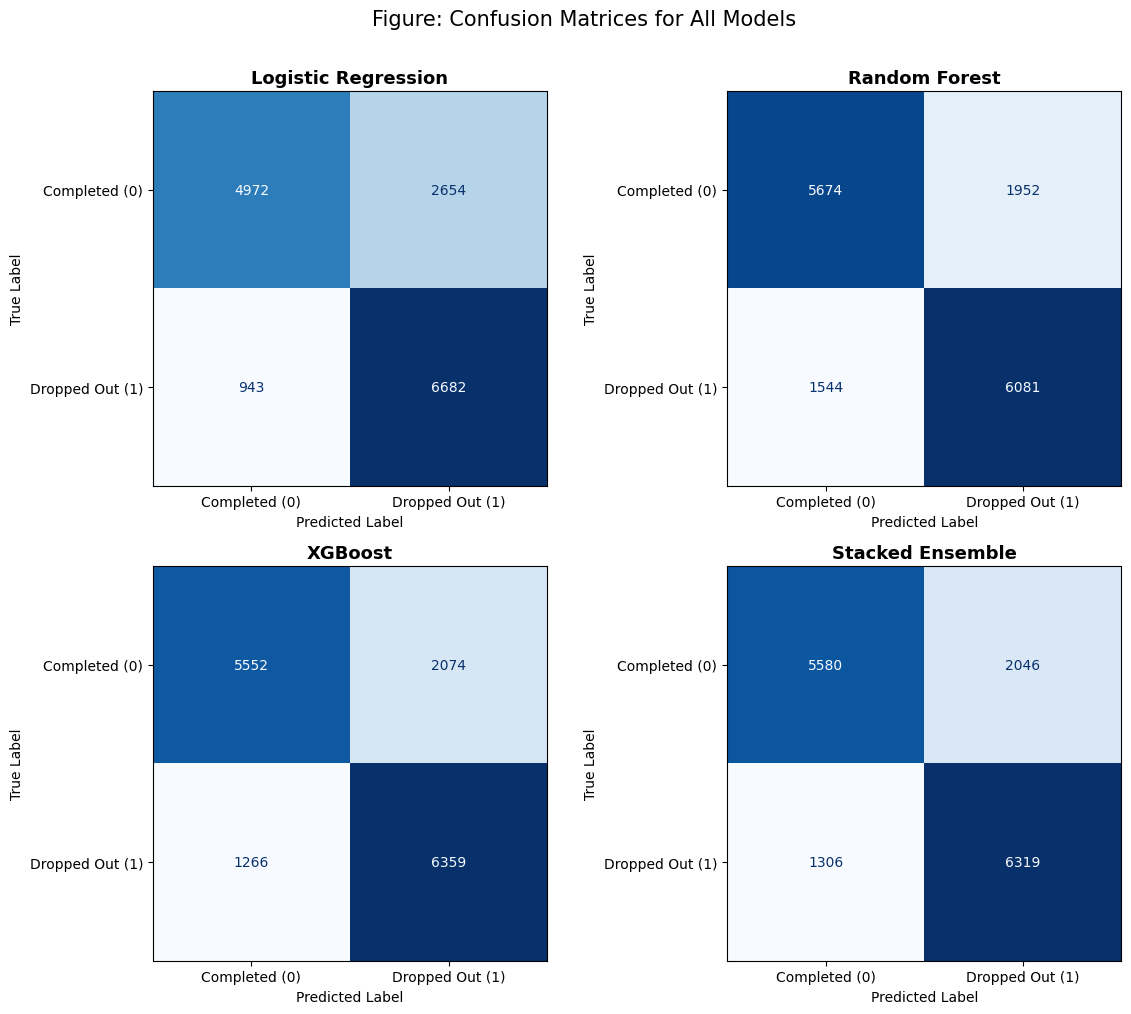

Saved: fig_confusion_matrices.png

Generating ROC curves...


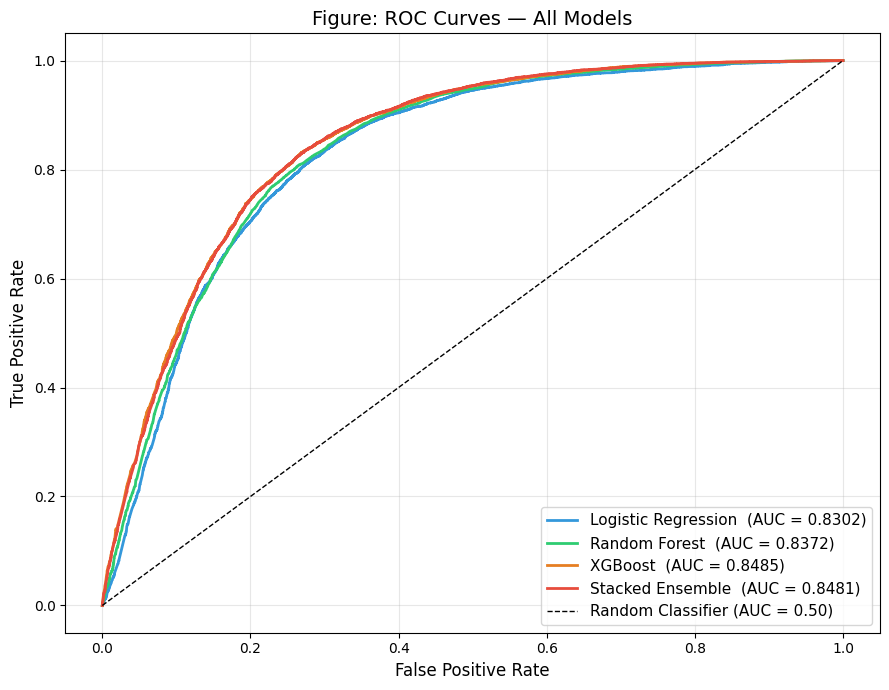

Saved: fig_roc_curves.png

Generating metric comparison bar chart...


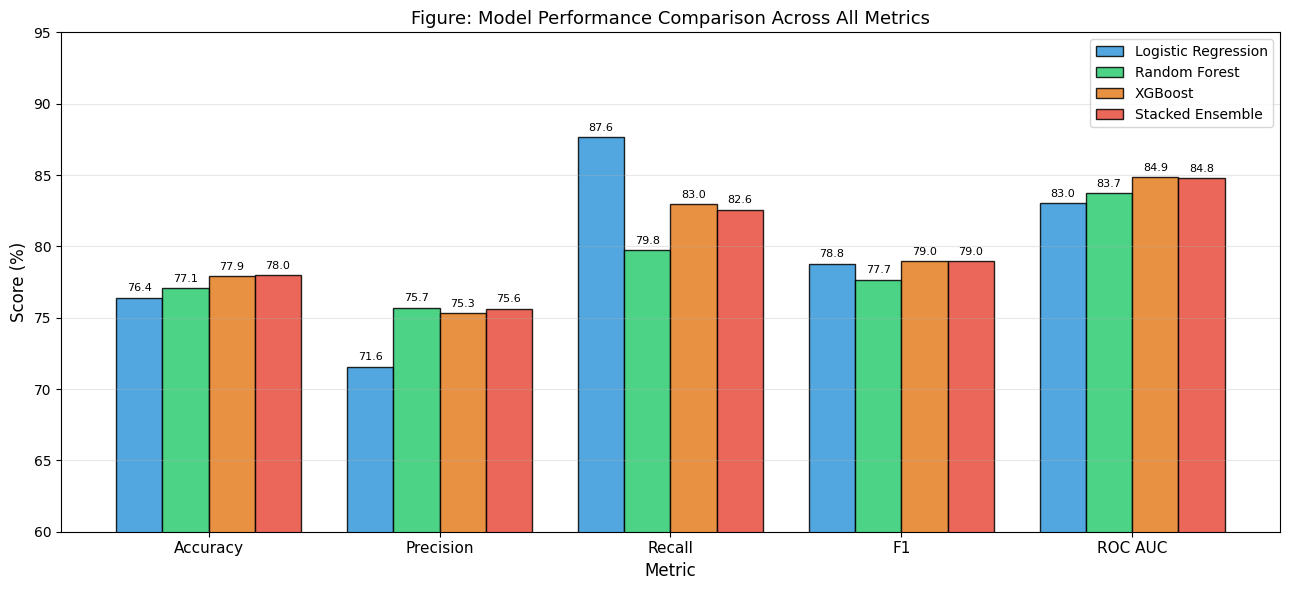

Saved: fig_metric_comparison.png

--- Classification Report: Stacked Ensemble ---
                 precision    recall  f1-score   support

  Completed (0)       0.81      0.73      0.77      7626
Dropped Out (1)       0.76      0.83      0.79      7625

       accuracy                           0.78     15251
      macro avg       0.78      0.78      0.78     15251
   weighted avg       0.78      0.78      0.78     15251


STEP 8 COMPLETE — ready for Step 9: SHAP Explainability


In [ ]:
# =============================================================================
# STEP 8: MODEL EVALUATION — PLOTS
# Predicting Student Dropout Risk in Online Learning
# Produces: Confusion matrices, ROC curves, bar chart comparison
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, auc, classification_report)
from xgboost import XGBClassifier
import warnings
warnings.filterwarnings("ignore")

# -----------------------------------------------------------------------------
# 8a. Load data and re-train models
# (Colab doesn't persist trained objects between cells, so we retrain quickly)
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv")
test  = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv")

feature_cols = [c for c in train.columns if c != "truth"]
X_train = train[feature_cols];  y_train = train["truth"]
X_test  = test[feature_cols];   y_test  = test["truth"]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print("=" * 70)
print("STEP 8: MODEL EVALUATION")
print("=" * 70)
print("\nRe-training models for evaluation plots...")

# FIXED PARAMETERS (matches Step 7 exactly):
#   n_estimators = 200  -> RF and XGBoost use the SAME value (not tuned)
#   random_state = 42   -> ALL models (reproducibility, not tuned)
#   learning_rate        -> XGBoost only; set to the value selected via the
#                           comparison in Step 7 (update BEST_LEARNING_RATE
#                           below to match the result printed there)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
BEST_LEARNING_RATE = 0.1  # <-- keep this in sync with Step 7's result

lr  = LogisticRegression(max_iter=1000, random_state=42).fit(X_train_s, y_train)
rf  = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1).fit(X_train_s, y_train)
xgb = XGBClassifier(n_estimators=200, learning_rate=BEST_LEARNING_RATE,
                    random_state=42, eval_metric="logloss").fit(X_train_s, y_train)

base_learners = [
    ("lr",  LogisticRegression(max_iter=1000, random_state=42)),
    ("rf",  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ("xgb", XGBClassifier(n_estimators=200, learning_rate=BEST_LEARNING_RATE,
                          random_state=42, eval_metric="logloss")),
]
stack = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=cv, passthrough=False, n_jobs=-1
).fit(X_train_s, y_train)

models = {
    "Logistic Regression": lr,
    "Random Forest":       rf,
    "XGBoost":             xgb,
    "Stacked Ensemble":    stack,
}
print("All models re-trained.\n")

# -----------------------------------------------------------------------------
# 8b. Confusion matrices (one per model, 2x2 grid)
# -----------------------------------------------------------------------------
print("Generating confusion matrices...")
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test_s)
    cm = confusion_matrix(y_test, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                                  display_labels=["Completed (0)", "Dropped Out (1)"])
    disp.plot(ax=axes[i], colorbar=False, cmap="Blues")
    axes[i].set_title(name, fontsize=13, fontweight="bold")
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("True Label")

plt.suptitle("Figure: Confusion Matrices for All Models", fontsize=15, y=1.01)
plt.tight_layout()
plt.savefig("/content/fig_confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_confusion_matrices.png")

# -----------------------------------------------------------------------------
# 8c. ROC curves (all models on one chart)
# -----------------------------------------------------------------------------
print("\nGenerating ROC curves...")
colors = ["#3498DB", "#2ECC71", "#E67E22", "#E74C3C"]
plt.figure(figsize=(9, 7))

for (name, model), color in zip(models.items(), colors):
    y_proba = model.predict_proba(X_test_s)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=color, lw=2,
             label=f"{name}  (AUC = {roc_auc:.4f})")

plt.plot([0, 1], [0, 1], "k--", lw=1, label="Random Classifier (AUC = 0.50)")
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)
plt.title("Figure: ROC Curves — All Models", fontsize=14)
plt.legend(loc="lower right", fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("/content/fig_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_roc_curves.png")

# -----------------------------------------------------------------------------
# 8d. Bar chart: metric comparison across all models
# -----------------------------------------------------------------------------
print("\nGenerating metric comparison bar chart...")
results = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/model_results.csv",
                      index_col="Model")
metrics = ["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]

x = np.arange(len(metrics))
width = 0.2
fig, ax = plt.subplots(figsize=(13, 6))

for i, (model_name, color) in enumerate(zip(results.index, colors)):
    vals = [results.loc[model_name, m] for m in metrics]
    bars = ax.bar(x + i * width, vals, width, label=model_name,
                  color=color, edgecolor="black", alpha=0.85)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() + 0.3,
                f"{bar.get_height():.1f}",
                ha="center", va="bottom", fontsize=8)

ax.set_xlabel("Metric", fontsize=12)
ax.set_ylabel("Score (%)", fontsize=12)
ax.set_title("Figure: Model Performance Comparison Across All Metrics", fontsize=13)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(60, 95)
ax.legend(fontsize=10)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("/content/fig_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_metric_comparison.png")

# -----------------------------------------------------------------------------
# 8e. Classification report for the best model (Stacked Ensemble)
# -----------------------------------------------------------------------------
print("\n--- Classification Report: Stacked Ensemble ---")
y_pred_stack = stack.predict(X_test_s)
print(classification_report(y_test, y_pred_stack,
                            target_names=["Completed (0)", "Dropped Out (1)"]))

print("\nSTEP 8 COMPLETE — ready for Step 9: SHAP Explainability")

In [ ]:
!pip install shap -q
print("SHAP ready.")


SHAP ready.


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
STEP 9: SHAP EXPLAINABILITY

Re-training Stacked Ensemble (this takes ~10 minutes)...
Stacked Ensemble trained.

Setting up SHAP KernelExplainer...
(Using 500-student sample for speed — this may take 5-10 minutes)
Computing SHAP values for 500 test students...


  0%|          | 0/500 [00:00<?, ?it/s]

SHAP values computed.

Generating SHAP summary plot (beeswarm)...


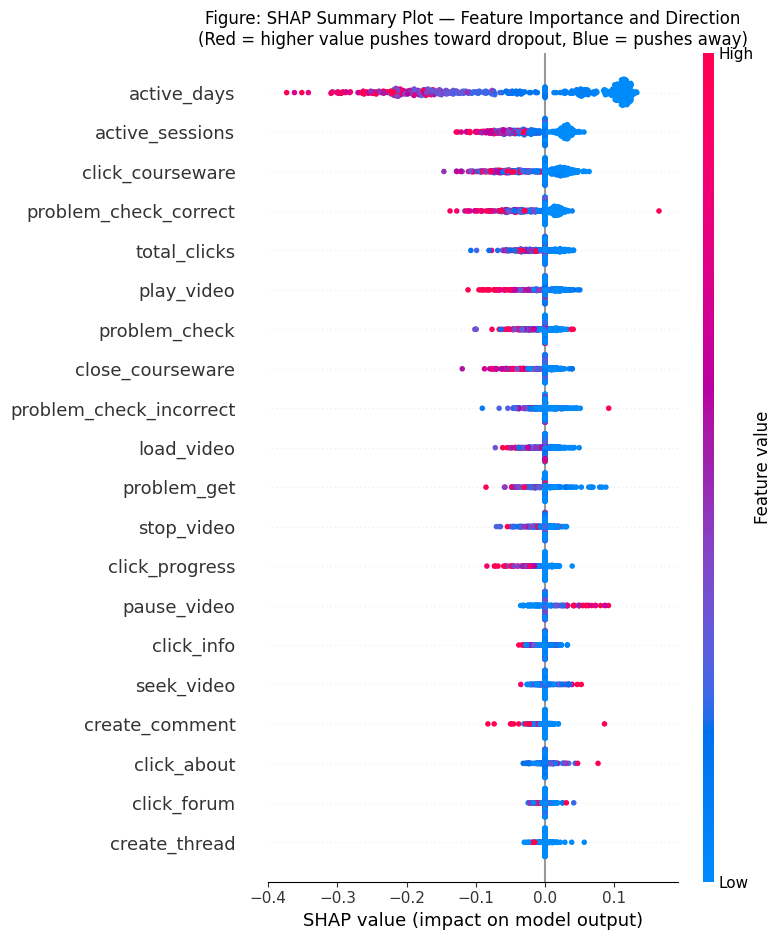

Saved: fig_shap_summary.png

Generating SHAP feature importance bar plot...


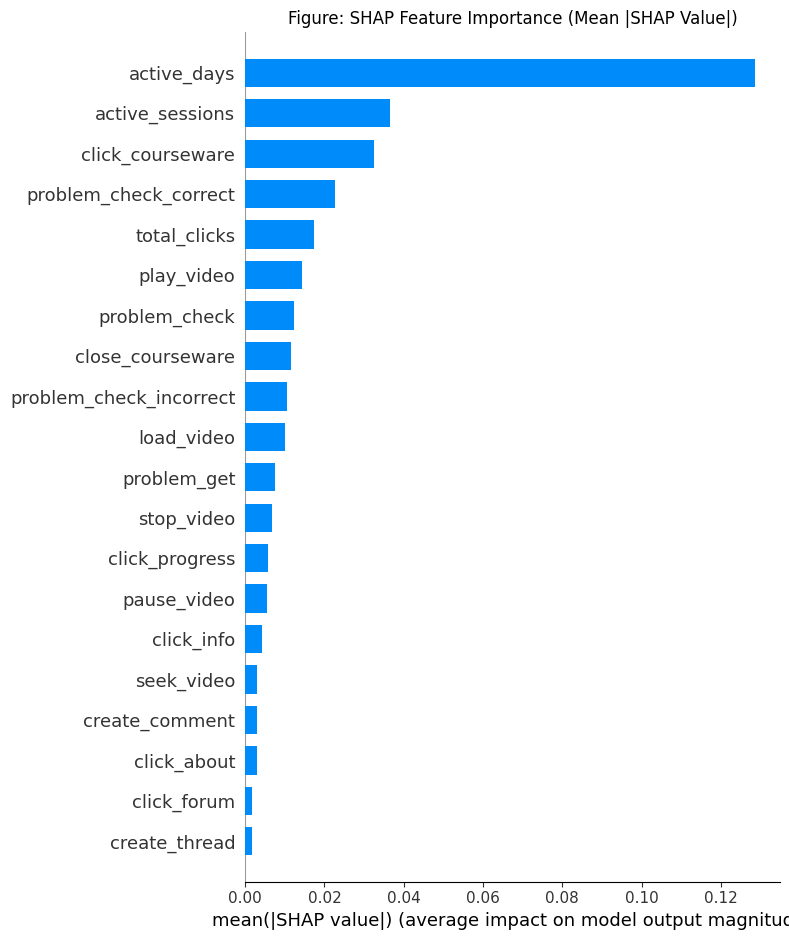

Saved: fig_shap_bar.png

Generating SHAP force plot for one example student...
Showing force plot for student index 381
Predicted dropout probability: 0.8675 (86.7%)


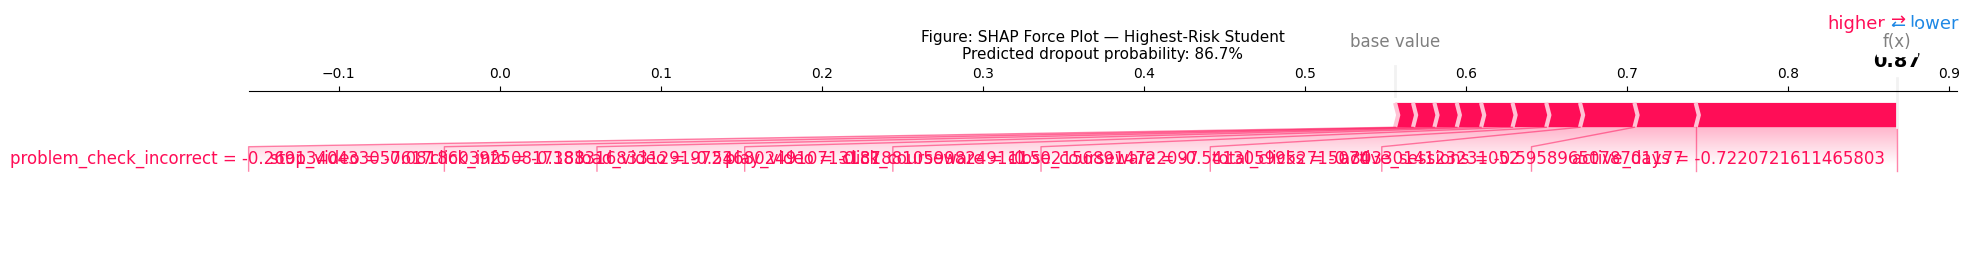

Saved: fig_shap_force.png

--- Top features by mean absolute SHAP value ---
active_days                0.1285
active_sessions            0.0366
click_courseware           0.0326
problem_check_correct      0.0226
total_clicks               0.0174
play_video                 0.0143
problem_check              0.0124
close_courseware           0.0115
problem_check_incorrect    0.0105
load_video                 0.0101
problem_get                0.0075
stop_video                 0.0068
click_progress             0.0059
pause_video                0.0056
click_info                 0.0043
seek_video                 0.0031
create_comment             0.0029
click_about                0.0029
click_forum                0.0018
create_thread              0.0017
problem_save               0.0015
reset_problem              0.0013

STEP 9 COMPLETE — ALL STEPS DONE!

Summary of all figures generated:
  fig_histograms.png          — Step 3: Feature distributions
  fig_boxplots.png            — Step 3: Outl

In [ ]:
# =============================================================================
# STEP 9: SHAP EXPLAINABILITY
# Predicting Student Dropout Risk in Online Learning
# Produces: SHAP summary plot, bar plot, and force plot for one student
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap
import warnings
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.model_selection import StratifiedKFold
from xgboost import XGBClassifier

# -----------------------------------------------------------------------------
# 9a. Load data and re-train the stacked ensemble
# -----------------------------------------------------------------------------
from google.colab import drive
drive.mount('/content/drive')

train = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/train_set.csv")
test  = pd.read_csv("/content/drive/MyDrive/MOOC_Thesis_Data/test_set.csv")

feature_cols = [c for c in train.columns if c != "truth"]
X_train = train[feature_cols];  y_train = train["truth"]
X_test  = test[feature_cols];   y_test  = test["truth"]

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

# Convert back to DataFrame so SHAP can display feature names
X_train_df = pd.DataFrame(X_train_s, columns=feature_cols)
X_test_df  = pd.DataFrame(X_test_s,  columns=feature_cols)

print("=" * 70)
print("STEP 9: SHAP EXPLAINABILITY")
print("=" * 70)
print("\nRe-training Stacked Ensemble (this takes ~10 minutes)...")

# FIXED PARAMETERS (matches Step 7 exactly):
#   n_estimators = 200  -> RF and XGBoost use the SAME value (not tuned)
#   random_state = 42   -> ALL models (reproducibility, not tuned)
#   learning_rate        -> XGBoost only; set to the value selected via the
#                           comparison in Step 7 (update BEST_LEARNING_RATE
#                           below to match the result printed there)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
BEST_LEARNING_RATE = 0.1  # <-- keep this in sync with Step 7's result

base_learners = [
    ("lr",  LogisticRegression(max_iter=1000, random_state=42)),
    ("rf",  RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)),
    ("xgb", XGBClassifier(n_estimators=200, learning_rate=BEST_LEARNING_RATE,
                          random_state=42, eval_metric="logloss")),
]
stack = StackingClassifier(
    estimators=base_learners,
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=cv, passthrough=False, n_jobs=-1
).fit(X_train_s, y_train)

print("Stacked Ensemble trained.\n")

# -----------------------------------------------------------------------------
# 9b. Set up SHAP explainer
#     We use a sample of 500 test students for SHAP to keep computation fast.
#     KernelExplainer works with any model (including stacking classifiers)
#     by treating the model as a black box and estimating feature contributions
#     using the Shapley value framework from cooperative game theory.
# -----------------------------------------------------------------------------
print("Setting up SHAP KernelExplainer...")
print("(Using 500-student sample for speed — this may take 5-10 minutes)")

# Background dataset: 100 random training samples used as the SHAP baseline
background = shap.sample(X_train_df, 100, random_state=42)

# Wrapper: SHAP needs a function that returns probabilities
def predict_proba_dropout(X):
    return stack.predict_proba(X)[:, 1]

explainer = shap.KernelExplainer(predict_proba_dropout, background)

# Sample 500 test students for SHAP values
X_sample = X_test_df.sample(500, random_state=42).reset_index(drop=True)
print(f"Computing SHAP values for {len(X_sample)} test students...")

shap_values = explainer.shap_values(X_sample, nsamples=100)
print("SHAP values computed.\n")

# -----------------------------------------------------------------------------
# 9c. SHAP Summary Plot (beeswarm)
#     Shows: which features matter most overall (y-axis = feature importance)
#     and in which direction (red = high feature value pushes toward dropout,
#     blue = low feature value pushes toward dropout)
# -----------------------------------------------------------------------------
print("Generating SHAP summary plot (beeswarm)...")
plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_sample, show=False)
plt.title("Figure: SHAP Summary Plot — Feature Importance and Direction\n"
          "(Red = higher value pushes toward dropout, Blue = pushes away)",
          fontsize=12)
plt.tight_layout()
plt.savefig("/content/fig_shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_shap_summary.png")

# -----------------------------------------------------------------------------
# 9d. SHAP Bar Plot (mean absolute SHAP values)
#     Cleaner version: ranks features by their average impact magnitude,
#     without the directional detail. Good for a quick ranking table.
# -----------------------------------------------------------------------------
print("\nGenerating SHAP feature importance bar plot...")
plt.figure(figsize=(10, 7))
shap.summary_plot(shap_values, X_sample, plot_type="bar", show=False)
plt.title("Figure: SHAP Feature Importance (Mean |SHAP Value|)", fontsize=12)
plt.tight_layout()
plt.savefig("/content/fig_shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_shap_bar.png")

# -----------------------------------------------------------------------------
# 9e. Force plot for one individual student
#     Shows exactly WHY the model predicted dropout (or completion) for one
#     specific student — which features pushed the prediction higher or lower.
#     This is the "local explanation" that could help an educator understand
#     why a specific student was flagged as at-risk.
# -----------------------------------------------------------------------------
print("\nGenerating SHAP force plot for one example student...")

# Pick the student with the highest predicted dropout probability
y_proba_sample = stack.predict_proba(X_sample)[:, 1]
highest_risk_idx = int(np.argmax(y_proba_sample))
predicted_prob = y_proba_sample[highest_risk_idx]

print(f"Showing force plot for student index {highest_risk_idx}")
print(f"Predicted dropout probability: {predicted_prob:.4f} ({predicted_prob*100:.1f}%)")

shap.initjs()
force = shap.force_plot(
    explainer.expected_value,
    shap_values[highest_risk_idx],
    X_sample.iloc[highest_risk_idx],
    matplotlib=True,
    show=False
)
plt.title(f"Figure: SHAP Force Plot — Highest-Risk Student\n"
          f"Predicted dropout probability: {predicted_prob*100:.1f}%",
          fontsize=11)
plt.tight_layout()
plt.savefig("/content/fig_shap_force.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: fig_shap_force.png")

# -----------------------------------------------------------------------------
# 9f. Print top features by SHAP importance
# -----------------------------------------------------------------------------
print("\n--- Top features by mean absolute SHAP value ---")
mean_shap = pd.Series(
    np.abs(shap_values).mean(axis=0),
    index=feature_cols
).sort_values(ascending=False)

print(mean_shap.round(4).to_string())

print("\n" + "=" * 70)
print("STEP 9 COMPLETE — ALL STEPS DONE!")
print("=" * 70)
print("""
Summary of all figures generated:
  fig_histograms.png          — Step 3: Feature distributions
  fig_boxplots.png            — Step 3: Outlier detection
  fig_correlation_matrix.png  — Step 3: Feature-target correlations
  fig_class_balance.png       — Step 4: Before/after class balancing
  fig_data_split.png          — Step 5: Train/test split distribution
  fig_confusion_matrices.png  — Step 8: All four model confusion matrices
  fig_roc_curves.png          — Step 8: ROC curves for all models
  fig_metric_comparison.png   — Step 8: Metric comparison bar chart
  fig_shap_summary.png        — Step 9: SHAP beeswarm (importance + direction)
  fig_shap_bar.png            — Step 9: SHAP feature importance ranking
  fig_shap_force.png          — Step 9: Individual student explanation

All results saved to: /content/drive/MyDrive/MOOC_Thesis_Data/
""")